<font size="6" color="black">Module 3 – Classification</font>

<img src="images_module03/module_03.png" width="600"/>


# Module Overview
***

In Lecture 1 we mentioned that the most common supervised learning tasks are:
- Regression (predicting continuous values)
- Classification (predicting categorical values, or "classes") 

In lecture 2 we explored a regression task, predicting housing values, using various algorithms such as Linear Regression, Decision Trees, and Random Forests (which will be explained in further detail in later lectures). Now we will turn our attention to classification systems. 

**Learning Goal:** At the end of this module, you should understand the basics principles of "classification" machine learning problems, including how to how to effectively evaluate model performance with various metrics, handle class imbalance, and interprete ROC and PR curves. 



In [2]:
# Common imports
import numpy as np
import os
import tarfile
from six.moves import urllib
import pandas as pd

# to make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

# Ignore useless warnings (see SciPy issue #5998)
import warnings
warnings.filterwarnings(action="ignore", message="^internal gelsd")

# Binary Classification

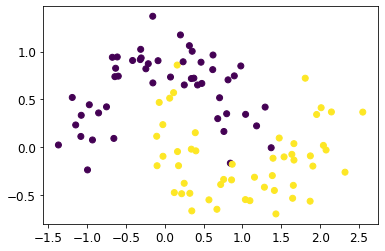

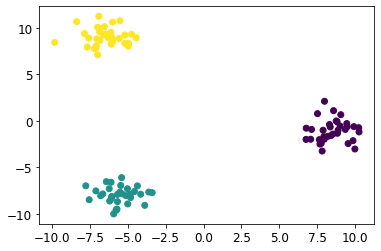

In [4]:
from sklearn.datasets import make_moons, make_blobs
X, y = make_moons(100, noise=0.2)
plt.scatter(X[:,0],X[:,1], c=y)
plt.show()

# Multiclass
X,y = make_blobs(100)
plt.scatter(X[:,0],X[:,1], c=y)
plt.show()

Just like a `LinearRegression` model, a `LogisticRegression` model computes a weighted sum of the input features (plus a bias term):
- But instead of outputting the result directly like the Linear Regression model does, it **outputs the logistic of this result**:

<img src="images_module03/logistic.png" width="600"/>


The Logistic (sigmoid) function squeezes the weighted sum ($\boldsymbol{x}^Tθ$) between 0 and 1 (Positive values close to 1, negative values close to 0). 
- When a value is above 0.5, it is classified as positive (and vice versa)

<img src="images_module03/sigmoid.png" width="600"/>

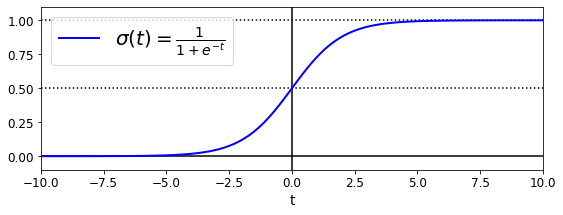

In [6]:
t = np.linspace(-10, 10, 100)
sig = 1 / (1 + np.exp(-t))

plt.figure(figsize=(9, 3))
plt.plot([-10, 10], [0, 0], "k-")
plt.plot([-10, 10], [0.5, 0.5], "k:")
plt.plot([-10, 10], [1, 1], "k:")
plt.plot([0, 0], [-1.1, 1.1], "k-")
plt.plot(t, sig, "b-", linewidth=2, label=r"$\sigma(t) = \frac{1}{1 + e^{-t}}$")
plt.xlabel("t")
plt.legend(loc="upper left", fontsize=20)
plt.axis([-10, 10, -0.1, 1.1])
plt.show()

Logits:
 [[-3.14627346 -1.85463894  5.00091241]
 [-1.99969226 -2.49167967  4.49137193]
 [-1.29754414  4.31426093 -3.01671679]
 [-3.31046102  5.36651183 -2.05605081]
 [-2.74676357  5.34194826 -2.59518469]]
Sigmoid output for class 0:
 [0.00028916 0.00151323 0.00363879 0.00017034 0.00030678]
Sigmoid output for class 1:
 [1.05217736e-03 9.25207041e-04 9.95709091e-01 9.99232507e-01
 9.99336227e-01]
Sigmoid output for class 2:
 [9.98658662e-01 9.97561558e-01 6.52122675e-04 5.97157042e-04
 3.56992085e-04]
Predictions:
 [2 2 1 1 1]


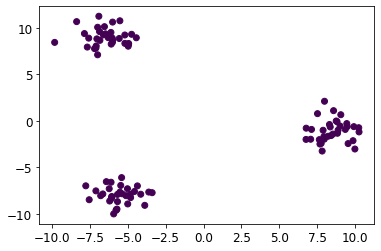

In [19]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()

# Train model
logreg.fit(X,y)

print("Logits:\n", logreg.decision_function(X)[0:5])
for c in range(3):
    print("Sigmoid output for class {}:\n".format(c), logreg.predict_proba(X)[0:5,c])
print("Predictions:\n", logreg.predict(X)[0:5])

#plt.scatter(X[:,0],X[:,1], c=y)
y_hat = logreg.predict(X)
correct = np.where(y_hat == y, 1, 0)

plt.scatter(X[:,0], X[:,1], c=correct)

The objective of training is to set the parameter vector $\theta$ so that the model estimates high probabilities for positive instances (y = 1) and low probabilities for negative instances (y = 0). 

This is the idea behind the logistic regression cost function, logloss: 

<img src="images_module03/logloss1.png" width="900"/>


<img src="images_module03/logloss2.png" width="600"/>

/var/folders/d2/814k5__d4r7603_t54sb6dr9m904k8/T/ipykernel_56533/1535402808.py:3: RuntimeWarning: divide by zero encountered in log
  neg_log_0 = -np.log(1-sigmoid_outputs)


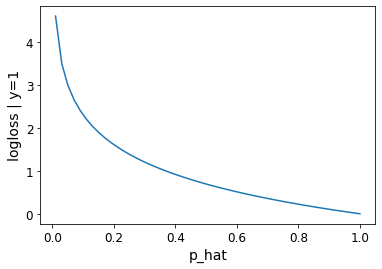

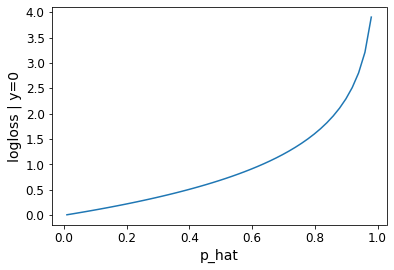

In [ ]:
sigmoid_outputs = np.linspace(0.01,1)
neg_log_1 = -np.log(sigmoid_outputs)
neg_log_0 = -np.log(1-sigmoid_outputs)

plt.plot(sigmoid_outputs, neg_log_1)
plt.xlabel('p_hat')
plt.ylabel('logloss | y=1')
plt.show()

plt.plot(sigmoid_outputs, neg_log_0)
plt.xlabel('p_hat')
plt.ylabel('logloss | y=0')
plt.show()


More thorough explanation:
- https://towardsdatascience.com/logistic-regression-detailed-overview-46c4da4303bc

Why not just use regression that predicts 1s and 0s?
- https://thestatsgeek.com/2015/01/17/why-shouldnt-i-use-linear-regression-if-my-outcome-is-binary/
- https://stats.stackexchange.com/questions/22381/why-not-approach-classification-through-regression

# MNIST

In this lecture we will be using the **MNIST dataset**, which is a set of 70,000 small images of digits handwritten by high school students and employees of the US Census Bureau. 

Each image is labeled with the digit it represents. This set has been studied so much that it is often called the “hello world” of Machine Learning: 
- whenever people come up with a new classification algorithm they are curious to see how it will perform on MNIST, and anyone who learns Machine Learning tackles this dataset sooner or later. 

Scikit-Learn provides many helper functions to download popular datasets. MNIST is one of them. The following code fetches the MNIST dataset.

In [38]:
#!pip install keras

     |████████████████████████████████| 1.7 MB 3.9 MB/s eta 0:00:01


In [40]:
#!pip install tensorflow

     |████████████████████████████████| 241.2 MB 23.9 MB/s eta 0:00:01
     |████████████████████████████████| 57 kB 9.0 MB/s  eta 0:00:01
     |████████████████████████████████| 1.6 MB 22.8 MB/s eta 0:00:01
     |████████████████████████████████| 438 kB 22.1 MB/s eta 0:00:01
     |████████████████████████████████| 65 kB 7.9 MB/s  eta 0:00:01
     |████████████████████████████████| 13.2 MB 15.7 MB/s eta 0:00:01
     |████████████████████████████████| 123 kB 23.6 MB/s eta 0:00:01
     |████████████████████████████████| 5.9 MB 13.2 MB/s eta 0:00:01
     |████████████████████████████████| 42 kB 3.2 MB/s  eta 0:00:01
     |████████████████████████████████| 3.5 MB 34.5 MB/s eta 0:00:01
     |████████████████████████████████| 781 kB 25.3 MB/s eta 0:00:01
     |████████████████████████████████| 151 kB 38.9 MB/s eta 0:00:01


In [3]:
from keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()
n_feats = 28*28


2022-10-02 19:28:07.589217: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
# Reshape and flatten data
X = np.vstack([X_train, X_test]).reshape(-1, n_feats)
y = np.hstack([y_train, y_test])
print("Old X shape:", X_train.shape)
print("New X shape:", X.shape)
print("y shape:", y.shape)

Old X shape: (60000, 28, 28)
New X shape: (70000, 784)
y shape: (70000,)


There are 70,000 images, and each image has 784 features. 
- This is because each image is **28 × 28 pixels**
- Each feature simply represents **one pixel’s intensity**, from 0 (white) to 255 (black). 

Let’s take a peek at one digit from the dataset. All you need to do is grab an instance’s feature vector, reshape it to a 28 × 28 array, and display it using Matplotlib’s `imshow()` function: 

ORIG SHAPE: (784,)


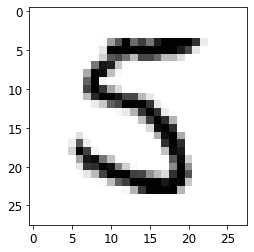

ORIG SHAPE: (784,)


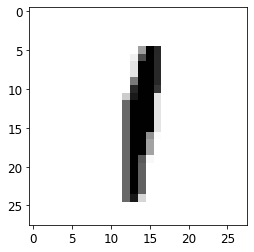

In [5]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

# Choose random digits
some_digit = X[3126]

some_digit_not5 = X[2154]

print("ORIG SHAPE:", some_digit.shape)
some_digit_image = some_digit.reshape(28, 28) #recast to 3 dims

plt.imshow(some_digit_image, cmap=matplotlib.cm.binary, interpolation="nearest")
plt.axis("on")
plt.show()


print("ORIG SHAPE:", some_digit_not5.shape)
some_digit_not5_image = some_digit_not5.reshape(28, 28) #recast to 3 dims

plt.imshow(some_digit_not5_image, cmap=matplotlib.cm.binary, interpolation="nearest")
plt.axis("on")

# save_fig("some_digit_plot")
plt.show()

In [6]:
some_digit

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   3,  97, 170, 253, 148, 191, 138, 222, 253,
       253, 255, 253, 205,  21,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,  24, 252, 252, 252, 252, 253, 252,
       252, 252, 252, 228, 185,  25,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,  45, 166, 183, 14

LABEL: 1


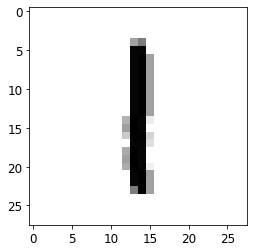

In [7]:
def plot_digit(data, axis='on'):
    image = data.reshape(28, 28)
    plt.imshow(image, cmap = matplotlib.cm.binary,
               interpolation="nearest")
    plt.axis(axis)
    
random_idx = np.random.randint(0,1000)
random_digit = X[random_idx]
print("LABEL:", y[random_idx])
plot_digit(random_digit)

In [8]:
def plot_digits(instances, images_per_row=10, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)
    images = [instance.reshape(size,size) for instance in instances]
    n_rows = (len(instances) - 1) // images_per_row + 1
    row_images = []
    n_empty = n_rows * images_per_row - len(instances)
    images.append(np.zeros((size, size * n_empty)))
    for row in range(n_rows):
        rimages = images[row * images_per_row : (row + 1) * images_per_row]
        row_images.append(np.concatenate(rimages, axis=1))
    image = np.concatenate(row_images, axis=0)
    plt.imshow(image, cmap = matplotlib.cm.binary, **options)
    plt.axis("off")

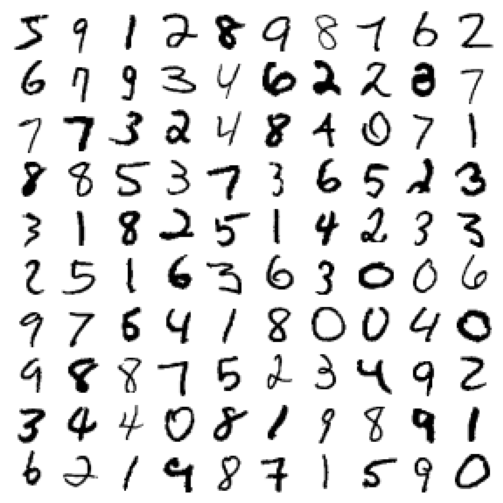

In [9]:
plt.figure(figsize=(9,9))
example_images = np.r_[X[:12000:600], X[13000:30600:600], X[30600:60000:590]]
plot_digits(example_images, images_per_row=10)
plt.show()

In [10]:
# Train test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(52500, 784)
(17500, 784)
(52500,)
(17500,)


In [11]:
# Extra shuffle for good measure
shuffle_index = np.random.permutation(52500)
X_train, y_train = X_train[shuffle_index], y_train[shuffle_index]

(array([5189., 5900., 5229., 5335., 5237., 4706., 5115., 5415., 5168.,
        5206.]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

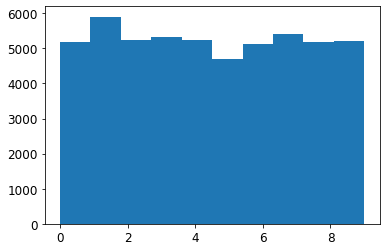

In [12]:
plt.hist(y_train)

(array([1714., 1977., 1761., 1806., 1587., 1607., 1761., 1878., 1657.,
        1752.]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

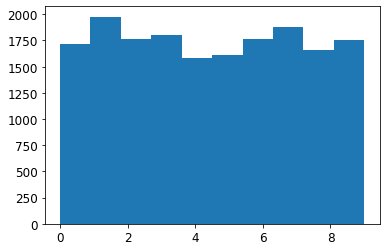

In [13]:
plt.hist(y_test)


Let’s simplify the problem for now and only try to identify one digit for example, the number 5. This “5-detector” will be an example of a **binary classifier , capable of distinguishing between just two classes, 5 and not-5.**

To start, we will use a Stochastic Gradient Descent Classifer, or `SGDClassifier`. This classifier has the advantage of being capable of handling very large datasets efficiently, in part because **SGD deals with training instances independently, one at a time**.

We will cover this in more detail in the 'training models' lecture, but for now here is a pretty descent blog post on the subject: https://sdsawtelle.github.io/blog/output/week2-andrew-ng-machine-learning-with-python.html

In [70]:
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)
y_train_5.sum()

4736

In [73]:
y_train[0:10]

array([6, 4, 2, 9, 7, 5, 1, 9, 6, 0], dtype=uint8)

In [74]:
y_train_5[0:10]

array([False, False, False, False, False,  True, False, False, False,
       False])

In [75]:
y_train_5.sum()/y_train_5.shape[0]

0.09020952380952381

(array([47764.,  4736.]),
 array([0. , 0.5, 1. ]),
 <BarContainer object of 2 artists>)

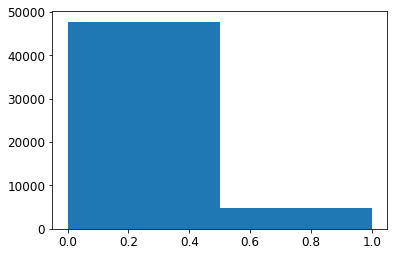

In [76]:
plt.hist(y_train_5.astype('int'), bins=2)

In [77]:
from sklearn.linear_model import SGDClassifier

# Add tol argument to prevent warnings
sgd_clf = SGDClassifier(max_iter=50, random_state=42, tol=-np.inf, loss='hinge')
sgd_clf.fit(X_train, y_train_5)

SGDClassifier(max_iter=50, random_state=42, tol=-inf)

In [78]:
idx = 10
print("Y:", y_train_5[idx])
sample_X = X_train[idx].reshape(1,-1)
sgd_clf.predict(sample_X)

Y: False


array([False])

In [79]:
print("COEFS:", sgd_clf.coef_.shape)
print("BIASES:", sgd_clf.intercept_.shape)

COEFS: (1, 784)
BIASES: (1,)


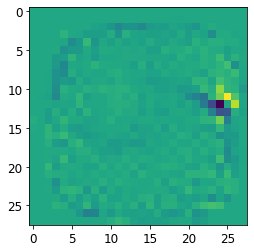

In [80]:
plt.imshow(sgd_clf.coef_.reshape(28,28))

Let’s use the `cross_val_score()` function to evaluate our SGDClassifier model, using K-fold cross-validation with three folds.
- Remember that K-fold cross-validation means **splitting the training set into K folds (in this case, three),**
- then making predictions and **evaluating them on each fold** using a model trained on the remaining folds 

In [83]:
from sklearn.model_selection import cross_val_score
cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy", verbose=5)

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.


[CV] END ................................ score: (test=0.963) total time=   2.5s


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    2.5s remaining:    0.0s


[CV] END ................................ score: (test=0.968) total time=   2.5s


[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    5.0s remaining:    0.0s


[CV] END ................................ score: (test=0.963) total time=   2.5s


[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    7.5s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    7.5s finished


array([0.96291429, 0.968     , 0.96268571])

#### Implementing Cross-Validation 
Occasionally you will need more control over the cross-validation process than Scikit-Learn provides off the shelf. 

In these cases, you can **implement cross-validation yourself.** The following code does roughly the same thing as Scikit-Learn’s `cross_val_score()` function, and it prints the same result: 



In [84]:
# Implement custom KFold CV 
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

skfolds = StratifiedKFold(n_splits=3, random_state=42, shuffle=True)

for train_index, test_index in skfolds.split(X_train, y_train_5):
    clone_clf = clone(sgd_clf)
    X_train_folds = X_train[train_index]
    y_train_folds = (y_train_5[train_index])
    X_test_fold = X_train[test_index]
    y_test_fold = (y_train_5[test_index])

    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_fold)
    n_correct = sum(y_pred == y_test_fold)
    print(n_correct / len(y_pred))

0.9650285714285715
0.9506285714285714
0.9589714285714286


Wow! Above **95% accuracy (ratio of correct predictions) on all cross-validation folds!** 

Does this seem suspicious to anyone? Well, before you get too excited, let’s look at **a very dumb classifier** that just classifies every single image in the “not-5” class:


In [85]:
from sklearn.base import BaseEstimator
class Never5Classifier(BaseEstimator):
    def fit(self, X, y=None):
        pass
    def predict(self, X):
        return np.zeros((len(X), 1), dtype=bool)

In [86]:
never_5_clf = Never5Classifier()
cross_val_score(never_5_clf, X_train, y_train_5, cv=3, scoring="accuracy")

array([0.90851429, 0.91102857, 0.90982857])

That’s right, **it has over 90% accuracy!**

This is simply because only about 10% of the images are 5s, so if you always guess that an image is not a 5, you will be right about 90% of the time. 

This demonstrates why **accuracy is generally not the preferred performance measure for classifiers, especially when you are dealing with skewed datasets (i.e., when some classes are much more frequent than others).**

# Evaluating a Classifier

#### Performance Measures 
Evaluating a classifier is often significantly trickier than evaluating a regressor, so we will spend a large part of this module on this topic.



## Confusion Matrix

A much better way to evaluate the performance of a classifier is to look at the **confusion matrix**. 
- The general idea is to count the number of times instances of class A are classified as class B (and vice versa) . 
- For example, to know the **number of times the classifier confused images of 5s with 3s**, you would look in the fifth row and third column of the confusion matrix. 

To compute the confusion matrix, you first need to have a set of **predictions so that they can be compared to the actual targets.** 
- You could make predictions on the test set, but let’s keep it untouched for now **(remember that you want to use the test set only at the very end of your project, once you have a classifier that you are ready to launch).** 

Instead, you can use the `cross_val_predict()` function: 
- Just like the `cross_val_score()` function, `cross_val_predict()` performs K-fold cross-validation, but instead of returning the evaluation scores, it returns the predictions made on each test fold. 
- This means that you get a **clean prediction for each instance in the training set** (“clean” meaning that the prediction is made by a model that never saw the data during training). 

Now you are ready to get the confusion matrix using the `confusion_matrix()` function. Just pass it the target classes (`y_train_5`) and the predicted classes (`y_train_pred`): 


In [87]:
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, verbose=10)
y_train_pred[0:10]

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    2.5s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    5.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    7.6s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    7.6s finished


array([False, False, False, False, False,  True, False, False, False,
       False])

In [88]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(y_train_5, y_train_pred)
df = pd.DataFrame(cm, index=['neg', 'pos'], columns=['neg','pos'])
# df['total'] = df.sum(axis=1)
df

,neg,pos
neg,46988,776
pos,1086,3650


In [90]:
df.sum(axis=1)

neg    47764
pos     4736
dtype: int64

In [91]:
df.sum(axis=0)

neg    48074
pos     4426
dtype: int64

Each row in a confusion matrix represents an actual class , while each column represents a predicted class . 
- The first row of this matrix considers non-5 images (the negative class ): 
    - ~47k of them were correctly classified as non-5s (they are called **true negatives** ), 
    - while the remaining ~700 were wrongly classified as 5s ( **false positives** ). 
- The second row considers the images of 5s (the positive class ): 
    - ~1000 were wrongly classified as non-5s ( **false negatives** ), 
    - while the remaining ~3600 were correctly classified as 5s ( **true positives** ). 
    
**A perfect classifier would have only true positives and true negatives, so its confusion matrix would have nonzero values only on its main diagonal (top left to bottom right):**


In [92]:
y_train_perfect_predictions = y_train_5

In [94]:
# Perfect classifier
cm_perfect = confusion_matrix(y_train_5, y_train_perfect_predictions)
pd.DataFrame(cm_perfect, index=['neg', 'pos'], columns=['neg','pos'])

,neg,pos
neg,47764,0
pos,0,4736


## Precision & Recall


The confusion matrix gives you a lot of information, but sometimes you may prefer **a more concise metric.** 

An interesting one to look at is the **accuracy of the positive predictions**; this is called the **precision** of the classifier:

- $\text{precision} = \frac{TP}{TP+FP}$ 
    - $TP$ is the number of true positives,
    - $FP$ is the number of false positives. 
    
Note that a trivial way to have perfect precision is to make one single positive prediction and ensure it is correct (precision = 1/1 = 100%). But this would not be very useful, since the classifier would ignore all but one positive instance. 

So precision is typically used along with another metric named **recall , also called sensitivity or the true positive rate (TPR)**. This is the ratio of positive instances that are correctly detected by the classifier. 

- $\text{recall} = \frac{TP}{TP+FN}$ 
    - $TP$ is the number of true positives,
    - $FN$ is the number of false negatives.
    
    
The diagram below shows TP, FP, TN, and FN in the context of a confusion matrix:

 <img src="images_module03/confusion_matrix.png" width="600"/>

In [95]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Accuracy of positive predictions
print(precision_score(y_train_5, y_train_pred))

# True positive rate (share of true positives correctly identified)
print(recall_score(y_train_5, y_train_pred))

0.824672390420244
0.7706925675675675


In [96]:
TP = cm[1,1]
FP = cm[0,1]
FN = cm[1,0]
prec = TP / (TP + FP)
rec = TP / (TP + FN)
print("PRECISION:", prec)
print("RECALL:", rec)

PRECISION: 0.824672390420244
RECALL: 0.7706925675675675


Now your 5-detector does not look as shiny as it did when you looked at its accuracy. 
- When it claims an image represents a 5, it is correct only 82% of the time
- However it only captures ~77% of all 5s!


It is often convenient to combine precision and recall into a single metric called the **F1 score**, in particular if you need a simple way to compare two classifiers. 
- The F1 score is the **harmonic mean of precision and recall**. 
- Whereas the regular mean treats all values equally, the **harmonic mean gives much more weight to low values.** 
- As a result, the classifier will **only get a high F1 score if both recall and precision are high.** 

 <img src="images_module03/f1_score.png" width="600"/>

In [97]:
from sklearn.metrics import f1_score
f1_score(y_train_5, y_train_pred)

0.7967692643527614

In [98]:
def calc_f1s(prec, rec):
    return 2*((prec*rec)/(prec+rec))

calc_f1s(prec, rec)

0.7967692643527614

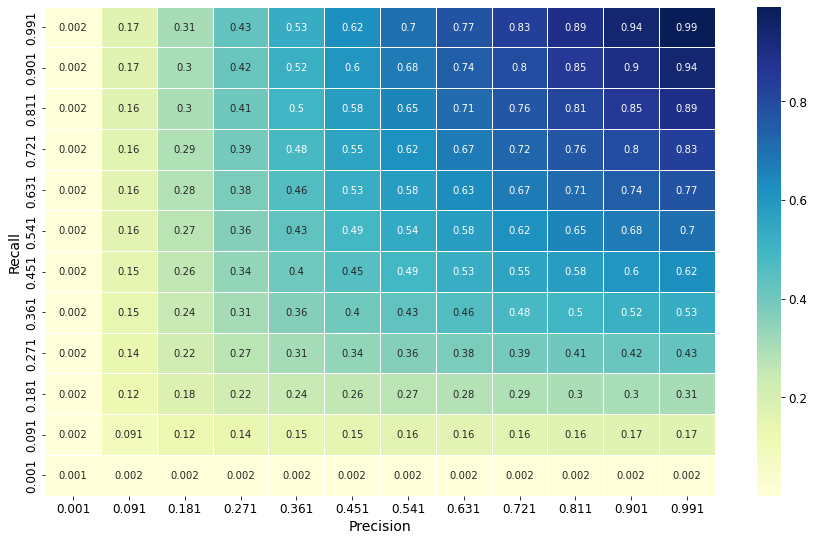

In [99]:
import itertools
import pandas as pd
import seaborn as sns

list1=list(np.round(np.arange(0.001, 1, 0.09), decimals=3))
data = list(itertools.product(list1, list1))
f1s = [calc_f1s(i[0], i[1]) for i in data]
df = pd.DataFrame({"Precision":[i[0] for i in data],
                   "Recall": [i[1] for i in data],
                   "F1": f1s
                  })

df_pivot = df.pivot(index='Recall', columns='Precision', values='F1')

# Plot hyperparam heatmap
plt.figure(figsize=(15,9))
sns.heatmap(df_pivot, cmap="YlGnBu", annot=True, linewidths=1, linecolor='white')
plt.gca().invert_yaxis()
plt.show()  

## Precision / Recall Tradeoff

The F1 score favors classifiers that have **similar precision and recall.** This is not always what you want: in some contexts you mostly care about precision, and in other contexts you really care about recall. 
- For example, if you trained a classifier to detect videos that are safe for kids, you would probably prefer a classifier that rejects many good videos (low recall) but keeps only safe ones (high precision), rather than a classifier that has a much higher recall but lets a few really bad videos show up in your product (in such cases, you may even want to add a human pipeline to check the classifier’s video selection). 
- On the other hand, suppose you train a classifier to detect shoplifters in surveillance images: it is probably fine if your classifier has only 30% precision as long as it has 99% recall (sure, the security guards will get a few false alerts, but almost all shoplifters will get caught). 

Unfortunately, you can’t have it both ways: **increasing precision reduces recall, and vice versa. This is called the precision/recall trade-off.**

To understand this trade-off, let’s look at how the SGDClassifier makes its classification decisions. For each instance, it computes a score based on a **decision function**. 
- If that score is greater than a threshold, it assigns the instance to the positive class; otherwise it assigns it to the negative class. 

The figure below shows a few digits positioned from the lowest score on the left to the highest score on the right. 
- Suppose the decision threshold is positioned at the central arrow (between the two 5s): you will find 4 true positives (actual 5s) on the right of that threshold, and 1 false positive (actually a 6). Therefore, with that threshold, the precision is 80% (4 out of 5). But out of 6 actual 5s, the classifier only detects 4, so the recall is 67% (4 out of 6). 
- If you raise the threshold (move it to the arrow on the right), the false positive (the 6) becomes a true negative, thereby increasing the precision (up to 100% in this case), but one true positive becomes a false negative, decreasing recall down to 50%. 
- Conversely, lowering the threshold increases recall and reduces precision. 

 <img src="images_module03/thresholds.png" width="600"/>

**NOTE:** Scikit-Learn does **NOT** let you set the threshold directly, but it does give you access to the decision scores that it uses to make predictions. 
- Instead of calling the classifier’s `predict()` method, you can call its `decision_function()` method, which returns a score for each instance, and then use any threshold you want to make predictions based on those scores.

In [100]:
from sklearn.linear_model import LogisticRegression

# Filter convergence warnings
from sklearn.exceptions import ConvergenceWarning
import warnings

warnings.filterwarnings('ignore', category=ConvergenceWarning)

lr_clf = LogisticRegression(max_iter=100)
lr_clf.fit(X_train, y_train_5)

LogisticRegression()

In [101]:
# SGDClassifier
y_raw = sgd_clf.decision_function([some_digit])
y_pred = sgd_clf.predict([some_digit])
print("SGD raw prediction 5:", y_raw)
print("SGD class prediction 5:", y_pred)
print()

y_raw = sgd_clf.decision_function([some_digit_not5])
y_pred = sgd_clf.predict([some_digit_not5])
print("SGD raw prediction NOT 5:", y_raw)
print("SGD class prediction NOT 5:", y_pred)



SGD raw prediction 5: [15440.33169987]
SGD class prediction 5: [ True]

SGD raw prediction NOT 5: [-47956.15855012]
SGD class prediction NOT 5: [False]


In [102]:
# LogReg
y_raw = lr_clf.predict_proba([some_digit])
y_pred = lr_clf.predict([some_digit])
print("LR raw prediction 5:", y_raw)
print("LR class prediction 5:", y_pred)
print()
y_raw = lr_clf.predict_proba([some_digit_not5])
y_pred = lr_clf.predict([some_digit_not5])
print("LR raw prediction NOT 5:", y_raw)
print("LR class prediction NOT 5:", y_pred)



LR raw prediction 5: [[0.03826375 0.96173625]]
LR class prediction 5: [ True]

LR raw prediction NOT 5: [[0.99658388 0.00341612]]
LR class prediction NOT 5: [False]


In [107]:
# Raise threshold to 20000
y_score = sgd_clf.decision_function([some_digit])

threshold = 0
print((y_score > threshold))

threshold = 20000
print((y_score > threshold))


[ True]
[False]


The SGDClassifier uses a **threshold equal to 0**, so the previous code returns the same result as the `predict()` method (i.e., True ). The image actually represents a 5, and the classifier detects it when the threshold is 0, but it misses it when the threshold is increased to 20,000. 

As we can see:
- INCREASE threshold -> INCREASE precision & DECREASE recall
    - FP decrease, FN increase
- DECREASE threshold -> DECREASE precision & INCREASE recall
    - FP increase, FN decrease
    
    
**How do we decide what threshold to choose?**
- For this, we need the **precision/recall** curve. To plot this curve, first we need to collect the decision function scores for all instances.

In [108]:
sgd_y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method="decision_function")
lr_y_scores = cross_val_predict(lr_clf, X_train, y_train_5, cv=3, method="predict_proba")
print(sgd_y_scores.shape)
print(lr_y_scores.shape)
# y_scores[0:10]

(52500,)
(52500, 2)


With these decision function scores, we can now use the `precision_recall_curve()` function to compute precision and recall for **all possible thresholds:** 

In [109]:
from sklearn.metrics import precision_recall_curve

# ?precision_recall_curve


In [110]:
sgd_precisions, sgd_recalls, sgd_thresholds = precision_recall_curve(y_train_5, sgd_y_scores)
lr_precisions, lr_recalls, lr_thresholds = precision_recall_curve(y_train_5, lr_y_scores[:,1]) # USE POSITIVE CLASS

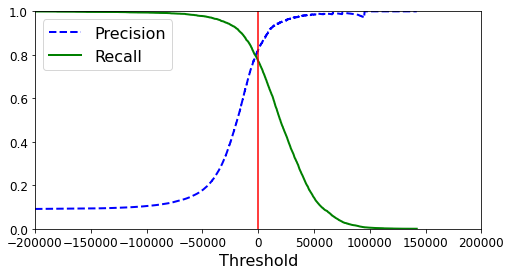

In [111]:
def plot_precision_recall_vs_threshold(precisions, recalls, thresholds, vl=0):
    plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
    plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
    plt.xlabel("Threshold", fontsize=16)
    plt.axvline(vl, c='r')
    plt.legend(loc="upper left", fontsize=16)
    plt.ylim([0, 1])

# SGD
plt.figure(figsize=(8, 4))
plot_precision_recall_vs_threshold(sgd_precisions, sgd_recalls, sgd_thresholds)
plt.xlim([-200000, 200000])
plt.show()

In [112]:
print(precision_score(y_train_5, sgd_y_scores>0))
print(recall_score(y_train_5, sgd_y_scores>0))

0.824672390420244
0.7706925675675675


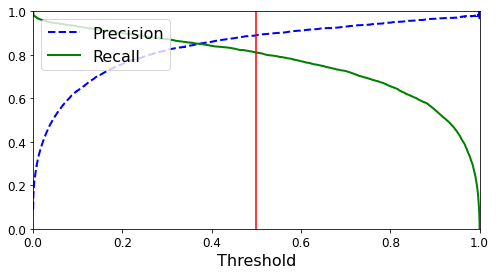

In [113]:
# LR
plt.figure(figsize=(8, 4))
plot_precision_recall_vs_threshold(lr_precisions, lr_recalls, lr_thresholds, vl=0.5)
plt.xlim([0, 1])
plt.show()

In [114]:
print(precision_score(y_train_5, np.argmax(lr_y_scores, axis=1)))
print(recall_score(y_train_5, np.argmax(lr_y_scores, axis=1)))

0.8901506373117034
0.8110219594594594


In [115]:
# Find index where pr = rc
for idx, i in enumerate(lr_thresholds):
    if lr_precisions[idx] == lr_recalls[idx]:
        print(idx, i)

47583 0.37201415178361863


In [116]:
print(precision_score(y_train_5, (lr_y_scores[:,1]>0.37548103015746326)))
print(recall_score(y_train_5, (lr_y_scores[:,1]>0.37548103015746326)))

0.8521499682270706
0.8494510135135135


You may wonder why the **precision curve is bumpier than the recall curve**. The reason is that precision may sometimes go down when you raise the threshold (although in general it will go up). On the other hand, recall can only go down when the threshold is increased, which explains why its curve looks smooth. 

Another way to select a good precision/recall trade-off is to **plot precision directly against recall**:

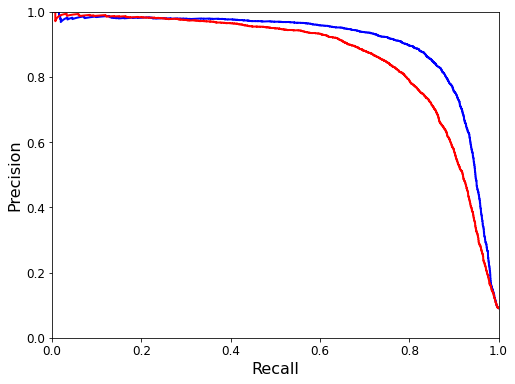

In [117]:
def plot_precision_vs_recall(precisions, recalls, c='red'):
    plt.plot(recalls, precisions, linewidth=2, c=c)
    plt.xlabel("Recall", fontsize=16)
    plt.ylabel("Precision", fontsize=16)
    plt.axis([0, 1, 0, 1])

plt.figure(figsize=(8, 6))
plot_precision_vs_recall(lr_precisions, lr_recalls, c='blue')
plot_precision_vs_recall(sgd_precisions, sgd_recalls)
plt.show()

You can see that precision really starts to fall sharply around 80% recall. You will probably want to **select a precision/recall trade-off just before that drop**. However the choice depends on your project. 

Remember, a high precision classifier is useless if recall is too low. **If someone says, “Let’s reach 99% precision,” you should ask, “At what recall?”** 


## ROC curves

The **receiver operating characteristic (ROC) curve** is another common tool used with binary classifiers. 
- It is very similar to the precision/recall curve, but instead of plotting precision versus recall, the ROC curve plots the **true positive rate (another name for recall) against the false positive rate (FPR).** 
- The FPR is the ratio of negative instances that are incorrectly classified as positive. It is equal to 1 – the true negative rate (TNR), which is the ratio of negative instances that are correctly classified as negative. The TNR is also called specificity . 
- Hence, the ROC curve plots **sensitivity (recall) versus 1 – specificity .** 

To plot the ROC curve, you first use the `roc_curve()` function to compute the TPR and FPR for various threshold values: 



In [118]:
from sklearn.metrics import roc_curve
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method="decision_function")

# roc_curve expects true labels (classes) and predicted scores (decision_function)
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

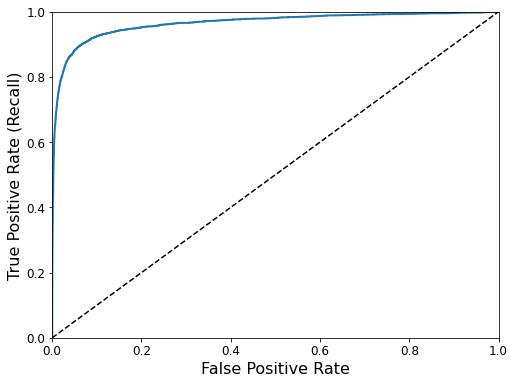

In [119]:
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.axis([0, 1, 0, 1])
    plt.xlabel('False Positive Rate', fontsize=16)
    plt.ylabel('True Positive Rate (Recall)', fontsize=16)

plt.figure(figsize=(8, 6))
plot_roc_curve(fpr, tpr)
# save_fig("roc_curve_plot")
plt.show()

Once again there is a trade-off: **the higher the recall (TPR), the more false positives (FPR) the classifier produces.** The dotted line represents the ROC curve of a *purely random classifier*; a good classifier stays as far away from that line as possible (toward the top-left corner). 

One way to compare classifiers is to measure the **area under the curve (AUC).** A perfect classifier will have a ROC AUC equal to 1, whereas a purely random classifier will have a ROC AUC equal to 0.5.

In [120]:
from sklearn.metrics import roc_auc_score

# roc_auc_score expects 
roc_auc_score(y_train_5, y_scores)

0.964496842725608

Since the ROC curve is so similar to the precision/recall (PR) curve, you may wonder how to decide which one to use. 
- As a rule of thumb, you should prefer the **PR curve whenever the positive class is rare or when you care more about the false positives than the false negatives.** Otherwise, use the ROC curve. 

For example:
- Looking at the previous ROC curve (and the ROC AUC score), you may think that the classifier is really good. But this is mostly because there are **few positives (5s) compared to the negatives (non-5s).** 
- In contrast, the PR curve makes it clear that the classifier has room for improvement (the curve could be closer to the top-left corner). 


A PR curve plots:
- `precision vs recall`

A receiver operating characteristic curve (ROC curve) plots:
- `True Positive Rate (recall) vs the False Positive Rate`
    - The TPR is just another name for recall (its also called sensitivity). 
        - Out of all the true target values, how many did we successfully predict.
    - The FPR (also known as fallout, and 1 - TNR, aka 1 - specificity) is defined as the number false positivies over the total number of negatives (false positives plus true negatives).
        - FPR is the chance we contaminate our sample with a false positive.
        
(By the way, the Wikipedia page for confusion matrix, and its linked pages exploring classification in depth, is a great resource.
https://en.wikipedia.org/wiki/Confusion_matrix)

**Examining the difference between ROC and PR Curves**:

Let us quickly denote:
- $Y$ as `true` label and $\hat{Y}$ as predicted label. 
- Precision: How many true successes are in all of our labeled successes. $P(Y=1|\hat{Y}=1)$
- Recall (or TPR): Out of all the true values that went in, how many came out. $P(\hat{Y}=1|Y=1)$
- FPR: The chance we contaminate our sample with a false positive. $P(\hat{Y}=1|Y=0)$

The important difference to note is that:
- For the ROC curve, (TPR and FPR), **the actual truth values are on the right hand side (they are conditioned on).**
- For the PR curve, **the precision has the predicted label on the right hand side.** So one term is conditioned on the truth, the other on the estimate. 

When will this make a difference?
- When the classes are imbalanced, or you care more about getting a true positive than a false negative. 

Imagine the difference between a recommendor system that might not recommend you a movie you actually would have liked (no big deal), and medical imaging algorithm that failes to detect cancer when its present in the image (a very big deal).
- Imagine if we look at a dataset with 100 cases in it. Either movies you want to watch, or people with cancer. And there are 100000 negatives (bad movies, healthy patients). 
- Two classifiers, A and B, are run, and both get 99 out of the 100 cases correct; their recall is the same. 
- But classifier A predicts 150 outcomes in total (99 true positives, 51 false positives), and classifier B predicts 1000 cases (99 true positives, 901 false positives). Their precision and FPR is different.
    - Classifier A: Recall=0.99, Precision=99/150=0.66, FPR=51/(51+100000)=0.0005
    - Classifier B: Recall=0.99, Precision=99/1000=0.099, FPR=901/(901+100000)=0.008

By looking at the ROC curve (Recall and FPR), the two classifiers look like they have similarly great performance! 
Same recall, and the FPR is absolutely tiny! But if we look at the PR curve (Recall and Precision), they look totally different - one has a precision of 0.66, the other <0.1!

With these sort of imbalanced class numbers, we can see why we might prefer PR curves in these cases.

In general:
- the ROC curve answers the question of how well the model performs with no knowledge of the class imbalance, 
- whilst the PR curve uses our estimated class imbalance baseline to inform us of how well our model performs, given the specific imbalance we provided it.


Let’s now train a `RandomForestClassifier` and compare its ROC curve and ROC AUC score to those of the `SGDClassifier` . 
- First, you need to get scores for each instance in the training set. But due to the way it works (as we will see in module 6), the `RandomForestClassifier` class does not have a `decision_function()` method. Instead, it has a `predict_proba()` method. 
- Scikit-Learn classifiers generally have one or the other, or both. 
- The `predict_proba()` method returns an array containing a row per instance and a column per class, each containing the probability that the given instance belongs to the given class (e.g., 70% chance that the image represents a 5)


In [121]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(n_estimators=10, random_state=42)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv=3,
                                    method="predict_proba")

In [122]:
y_scores_forest = y_probas_forest[:, 1] # score = proba of positive class
fpr_forest, tpr_forest, thresholds_forest = roc_curve(y_train_5,y_scores_forest)

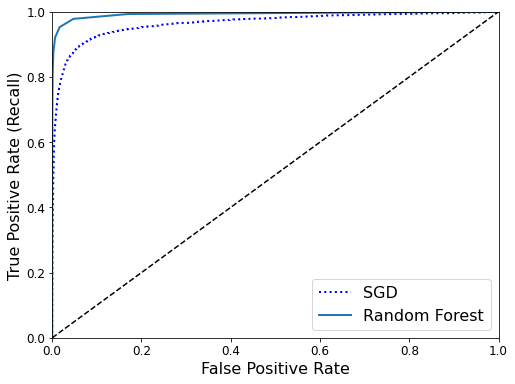

In [123]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, "b:", linewidth=2, label="SGD")
plot_roc_curve(fpr_forest, tpr_forest, "Random Forest")
plt.legend(loc="lower right", fontsize=16)
# save_fig("roc_curve_comparison_plot")
plt.show()

In [124]:
roc_auc_score(y_train_5, y_scores_forest)

0.9924592714397308

In [125]:
y_train_pred_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv=3)
precision_score(y_train_5, y_train_pred_forest)

0.987153134635149

In [126]:
recall_score(y_train_5, y_train_pred_forest)

0.8112331081081081

You now know how to:
- train binary classifiers, 
- choose the appropriate metric for your task, 
- evaluate your classifiers using cross-validation, 
- select the precision/recall trade-off that fits your needs, 
- and use ROC curves and ROC AUC scores to compare various models. 

Now let’s try to detect more than just the 5s. 


# Multiclass classification

Whereas binary classifiers distinguish between two classes, **multiclass classifiers** (also called multinomial classifiers) can distinguish between more than two classes. 
- Some algorithms (such as SGD classifiers, Random Forest classifiers, and naive Bayes classifiers) are capable of handling multiple classes natively. 
- Others (such as Logistic Regression or Support Vector Machine classifiers) are **strictly binary classifiers.** 

However, there are various strategies that you can use to perform multiclass classification with multiple binary classifiers. 

**One vs the Rest:**

One way to create a system that can classify the digit images into 10 classes (from 0 to 9) is to train 10 binary classifiers, one for each digit (a 0-detector, a 1-detector, a 2-detector, and so on). 
- When you want to classify an image, you get the decision score from each classifier for that image and you select the class whose classifier outputs the highest score. This is called the **one-versus-the-rest (OvR) strategy (also called one-versus-all)**. 

**One vs All:**

Another strategy is to train a binary classifier for every pair of digits: one to distinguish 0s and 1s, another to distinguish 0s and 2s, another for 1s and 2s, and so on. This is called the **one-versus-one (OvO) strategy**. 
- If there are N classes, you need to train **N × (N – 1) / 2 classifiers**. For the MNIST problem, this means training 45 binary classifiers! 
- When you want to classify an image, you have to run the image through all 45 classifiers and see which class wins the most duels. 
- The main advantage of OvO is that each classifier only needs to be trained on the part of the training set for the two classes that it must distinguish. 

Some algorithms (such as Support Vector Machine classifiers) **scale poorly with the size of the training set.** For these algorithms OvO is preferred because it is faster to train many classifiers on small training sets than to train few classifiers on large training sets. **For most binary classification algorithms (like logistic regression), however, OvR is preferred.** 
- Scikit-Learn detects when you try to use a binary classification algorithm for a multiclass classification task, and it **automatically runs OvR or OvO, depending on the algorithm.**

Let’s try this with a Support Vector Machine classifier, using the `sklearn.svm.SVC` class: 




## SVM Classifier - OvO

Under the hood (using default settings), Scikit-Learn uses the OvO strategy: 
- it trains 45 binary classifiers, 
- calculates the decision scores for a given image, 
- and selects the class that wins the most duels. 

If you call the `decision_function()` method, you will see that it returns **10 scores per instance (one score per class):** 

See docs for multiclass SVC: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

In [127]:
from sklearn.svm import SVC
?SVC

In [128]:
X_train.shape

(52500, 784)

In [129]:
%%time
# 3 minute training time if run with full dataset!!!!!
svm_clf = SVC()
svm_clf.fit(X_train[0:5000], y_train[0:5000])
pred = svm_clf.predict([some_digit])
pred

CPU times: user 2.87 s, sys: 27.1 ms, total: 2.9 s
Wall time: 2.9 s


array([5], dtype=uint8)

This code trains the `SVC` on the training set using the original target classes from 0 to 9 ( `y_train` ), instead of the 5-versus-the-rest target classes ( `y_train_5` ). Then it makes a prediction (a correct one in this case). 

Under the hood, Scikit-Learn actually used the OvO strategy: 
- it trained 45 binary classifiers, 
- got their decision scores for the image, 
- and selected the class that won the most duels. 

If you call the `decision_function()` method, you will see that it returns 10 scores per instance (instead of just 1). That’s one score per class: 

In [132]:
some_digit_scores = svm_clf.decision_function([some_digit])
print(svm_clf.classes_)
print(some_digit_scores)
print(np.argmax(some_digit_scores))

[0 1 2 3 4 5 6 7 8 9]
[[ 3.81011986  1.7132813   5.2423395   7.28435103  1.71427311  9.30480058
   6.18485231 -0.29146282  8.28515001  1.71514082]]
5


**NOTE:** When a classifier is trained, it stores the list of target classes in its `classes_` attribute, ordered by value. In this case, the index of each class in the `classes_` array conveniently matches the class itself (e.g., the class at index 5 happens to be class 5 ), but in general you won’t be so lucky. 


## SVM Classifier - OvR

If you want to force Scikit-Learn to use one-versus-one or one-versus-the-rest, you can use the `OneVsOneClassifier` or `OneVsRestClassifier` classes. 
- Simply create an instance and pass a classifier to its constructor (it does not even have to be a binary classifier). 
- For example, this code creates a multiclass classifier using the OvR strategy, based on an `SVC`

In [133]:
X_train.shape

(52500, 784)

In [134]:
%%time
# NOTE: This is very slow with SVC
# 43 minute training time if run with full dataset!!!!!
from sklearn.multiclass import OneVsRestClassifier
svm_ovr_clf = OneVsRestClassifier(SVC())
svm_ovr_clf.fit(X_train[0:5000], y_train[0:5000])
pred = svm_ovr_clf.predict([some_digit])
pred

CPU times: user 10.4 s, sys: 146 ms, total: 10.6 s
Wall time: 10.6 s


array([5], dtype=uint8)

In [135]:
some_digit_scores = svm_ovr_clf.decision_function([some_digit])
print(some_digit_scores)
print(np.argmax(some_digit_scores))

[[-1.61737623 -1.9943998  -1.38149245 -0.91462606 -1.81206032  0.37878275
  -1.41262949 -2.05045758 -0.80019926 -2.56072018]]
5


In [139]:
y_train[8]

6

In [140]:
pred = svm_ovr_clf.decision_function([X_train[8]])
pred

array([[-2.0862902 , -2.16242533, -1.00018742, -2.21855603, -1.404493  ,
        -1.26336412,  1.48330849, -2.48192911, -1.69459092, -2.30512768]])

In [141]:
np.argmax(pred)

6

In [142]:
svm_ovr_clf.classes_

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [143]:
svm_ovr_clf.predict([some_digit])

array([5], dtype=uint8)

In [144]:
len(svm_ovr_clf.estimators_)

10

In [147]:
svm_ovr_clf.estimators_[0]

SVC()

## SGD Classifier

`SGDClassifier` does not have to run OvR or OvO because it can directly classify instances into multiple classes. 

In [148]:
%%time
from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(loss='hinge', max_iter=5, tol=-np.inf,random_state=42)
sgd_clf.fit(X_train, y_train)
pred = sgd_clf.predict([some_digit])
pred

CPU times: user 3.66 s, sys: 94.2 ms, total: 3.76 s
Wall time: 3.76 s


array([5], dtype=uint8)

In [149]:
sgd_clf.coef_.shape

(10, 784)

In [150]:
sgd_clf.classes_

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [151]:
sgd_clf.classes_[5]

5

In [152]:
some_digit_scores = sgd_clf.decision_function([some_digit])
print(some_digit_scores)
print(np.argmax(some_digit_scores))

[[ -450777.51035466  -631850.39747985  -268150.90086243  -240945.66653729
   -622192.46156819   125784.50088641  -201991.29749604 -1179143.46250845
    -50872.90820106 -1252136.58754066]]
5


You can see that the classifier is **fairly confident about its prediction:**
- almost all scores are largely negative, while class 5 has a score of 125784.5. 
- The closest other possibility is class 8, which gets a score of -50872.9. 

Now of course you want to evaluate this classifier. As usual, you can use cross-validation. Use the `cross_val_score()` function to evaluate the SGDClassifier ’s accuracy: 

In [153]:
cross_val_score(sgd_clf, X_train[0:5000], y_train[0:5000], cv=3, scoring='accuracy')

array([0.83503299, 0.81463707, 0.83433373])

It gets over 81% on all test folds. 

If you used a random classifier, **you would get 10% accuracy**, so this is not such a bad score, but you can still do much better. 
- Simply scaling the inputs (as discussed in module 2) increases accuracy above 87%: 


In [154]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[0:5000])
cross_val_score(sgd_clf, X_train_scaled, y_train[0:5000], cv=3, scoring='accuracy')

array([0.87222555, 0.89682064, 0.89555822])

## RandomForestClassifier
Now lets train a multi-class model using `RandomForestClassifier` and the entire training dataset.

Note that instead of calling `decision_function()`, we call `predict_proba()`. That's because RFC outputs a prediction score from 0 to 1 for binary classification problems.

In [155]:
%%time
from sklearn.ensemble import RandomForestClassifier
rf_clf = RandomForestClassifier(n_estimators=1)
rf_clf.fit(X_train, y_train)

CPU times: user 375 ms, sys: 51 ms, total: 426 ms
Wall time: 425 ms


RandomForestClassifier(n_estimators=1)

In [156]:
pred = rf_clf.predict([some_digit])
pred

array([5], dtype=uint8)

In [157]:
some_digit_scores = rf_clf.predict_proba([some_digit])
print(some_digit_scores)
print(np.argmax(some_digit_scores))

[[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]]
5


In [158]:
from sklearn.metrics import classification_report
y_hat = rf_clf.predict(X_train)
print(classification_report(y_train, y_hat))

              precision    recall  f1-score   support

           0       0.96      0.96      0.96      5191
           1       0.97      0.98      0.97      5918
           2       0.93      0.93      0.93      5201
           3       0.92      0.91      0.91      5348
           4       0.93      0.94      0.93      5149
           5       0.91      0.91      0.91      4736
           6       0.95      0.95      0.95      5173
           7       0.94      0.94      0.94      5407
           8       0.89      0.89      0.89      5138
           9       0.91      0.91      0.91      5239

    accuracy                           0.93     52500
   macro avg       0.93      0.93      0.93     52500
weighted avg       0.93      0.93      0.93     52500



## Compare models with Scaled Data

In [159]:
from sklearn.preprocessing import StandardScaler

# Models
svm_clf = SVC()
lr_clf  = LogisticRegression(max_iter=5)
sgd_clf = SGDClassifier(loss='hinge', max_iter=5, tol=-np.inf,random_state=42)
rf_clf  = RandomForestClassifier(n_estimators=5, max_depth=8)

# Sample and scale
scaler = StandardScaler()
X_train_sample, y_train_sample = X_train[0:10000], y_train[0:10000]
X_train_sample_scaled = scaler.fit_transform(X_train_sample.astype(np.float64))

In [160]:
# Models with unscaled data
svm_scores     = cross_val_score(svm_clf, X_train_sample, y_train_sample, cv=5, scoring="accuracy", verbose=1, n_jobs=-1)
lr_scores      = cross_val_score(lr_clf, X_train_sample, y_train_sample, cv=5, scoring="accuracy", verbose=1, n_jobs=-1)
sgd_scores     = cross_val_score(sgd_clf, X_train_sample, y_train_sample, cv=5, scoring="accuracy", verbose=1, n_jobs=-1)
rf_scores      = cross_val_score(rf_clf, X_train_sample, y_train_sample, cv=5, scoring="accuracy", verbose=1, n_jobs=-1)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:   21.4s remaining:   32.1s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   21.5s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
/Users/Carl/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/Carl/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS

In [161]:
# Models with scaled data
svm_scores_scaled     = cross_val_score(svm_clf, X_train_sample_scaled, y_train_sample, cv=5, scoring="accuracy", verbose=1, n_jobs=-1)
lr_scores_scaled      = cross_val_score(lr_clf, X_train_sample_scaled, y_train_sample, cv=5, scoring="accuracy", verbose=1, n_jobs=-1)
sgd_scores_scaled     = cross_val_score(sgd_clf, X_train_sample_scaled, y_train_sample, cv=5, scoring="accuracy", verbose=1, n_jobs=-1)
rf_scores_scaled      = cross_val_score(rf_clf, X_train_sample_scaled, y_train_sample, cv=5, scoring="accuracy", verbose=1, n_jobs=-1)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:   27.7s remaining:   41.5s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   27.8s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
/Users/Carl/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/Carl/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS

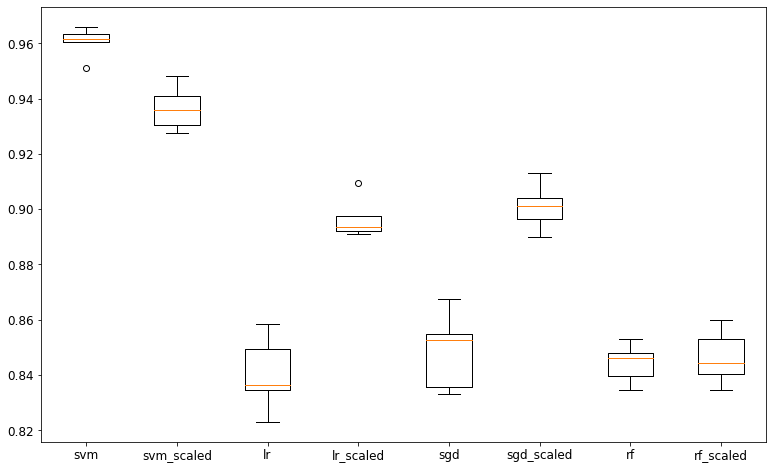

In [162]:
model_scores = [
    ('svm', svm_scores),
    ('svm_scaled', svm_scores_scaled),
    ('lr', lr_scores),
    ('lr_scaled', lr_scores_scaled),
    ('sgd', sgd_scores),
    ('sgd_scaled', sgd_scores_scaled),
    ('rf', rf_scores),
    ('rf_scaled', rf_scores_scaled)
]

# Plot scores
plt.figure(figsize=(13,8))
plt.boxplot([mod[1] for mod in model_scores],
            labels=[mod[0] for mod in model_scores])
plt.show()


## Error Analysis

If this were a real project, you would now follow the steps in your Machine Learning project checklist. 
- You’d explore data preparation options, try out multiple models (shortlisting the best ones and fine-tuning their hyperparameters using GridSearchCV), and automate as much as possible. 

Here, we will assume that you have found a promising model and you want to find ways to improve it. Let's first look at the `classification_report` output:

In [165]:
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train, cv=3)
print(classification_report(y_train, y_train_pred))

              precision    recall  f1-score   support

           0       0.89      0.98      0.93      5191
           1       0.95      0.95      0.95      5918
           2       0.92      0.83      0.88      5201
           3       0.85      0.86      0.86      5348
           4       0.78      0.91      0.84      5149
           5       0.85      0.75      0.79      4736
           6       0.93      0.90      0.91      5173
           7       0.84      0.93      0.88      5407
           8       0.71      0.85      0.77      5138
           9       0.89      0.57      0.69      5239

    accuracy                           0.86     52500
   macro avg       0.86      0.85      0.85     52500
weighted avg       0.86      0.86      0.85     52500



The next thing we should do is to analyze the types of errors it makes. First, **look at the confusion matrix.** 
- You need to make predictions using the `cross_val_predict()` function, then call the `confusion_matrix()` function, just like you did earlier: 


In [166]:
conf_mx = confusion_matrix(y_train, y_train_pred)
conf_mx

array([[5062,    2,   16,    8,    7,   16,   32,    3,   42,    3],
       [   1, 5603,   28,   27,   10,   24,   17,   15,  191,    2],
       [ 116,   78, 4326,   85,   81,   30,  128,   75,  268,   14],
       [  59,   16,   92, 4626,   19,  199,   35,   71,  192,   39],
       [  24,   23,   21,   12, 4706,   14,   43,   22,  149,  135],
       [ 132,   15,   41,  359,  126, 3543,   76,   31,  363,   50],
       [ 102,   18,   46,   12,  155,   77, 4673,    5,   85,    0],
       [  46,   20,   47,   21,   66,    7,    6, 5021,   70,  103],
       [  75,  124,   47,  148,   94,  197,   33,   38, 4347,   35],
       [  68,   27,   16,  138,  778,   75,    2,  719,  427, 2989]])

That’s a lot of numbers. It’s often more convenient to look at an image representation of the confusion matrix, using Matplotlib’s `matshow()` function: 


In [167]:
def plot_confusion_matrix(matrix):
    """If you prefer color and a colorbar"""
    fig = plt.figure(figsize=(8,8))
    ax = fig.add_subplot(111)
    cax = ax.matshow(matrix)
    fig.colorbar(cax)

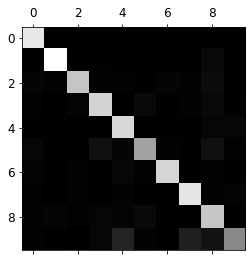

In [168]:
plt.matshow(conf_mx, cmap=plt.cm.gray)
plt.show()

This confusion matrix looks pretty good, since **most images are on the main diagonal, which means that they were classified correctly.** 
- The 5s look slightly darker than the other digits, which could mean that there are fewer images of 5s in the dataset or that the classifier does not perform as well on 5s as on other digits. In fact, you can verify that both are the case. 

Let’s focus the plot on the errors. 
- First, you need to **divide each value in the confusion matrix by the number of images in the corresponding class** so that you can compare error rates instead of absolute numbers of errors (which would make abundant classes look unfairly bad): 


In [169]:
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums

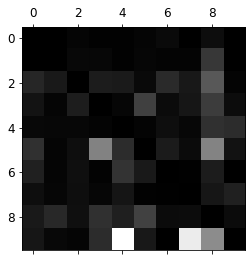

In [170]:
np.fill_diagonal(norm_conf_mx, 0)
plt.matshow(norm_conf_mx, cmap=plt.cm.gray)
plt.show()

In [171]:
norm_conf_mx

array([[0.        , 0.00038528, 0.00308226, 0.00154113, 0.00134849,
        0.00308226, 0.00616452, 0.00057792, 0.00809093, 0.00057792],
       [0.00016898, 0.        , 0.00473133, 0.00456235, 0.00168976,
        0.00405542, 0.00287259, 0.00253464, 0.03227442, 0.00033795],
       [0.0223034 , 0.01499712, 0.        , 0.01634301, 0.01557393,
        0.00576812, 0.02461065, 0.0144203 , 0.05152855, 0.00269179],
       [0.01103216, 0.00299177, 0.01720269, 0.        , 0.00355273,
        0.03721017, 0.0065445 , 0.01327599, 0.03590127, 0.00729245],
       [0.0046611 , 0.00446689, 0.00407846, 0.00233055, 0.        ,
        0.00271897, 0.00835114, 0.00427267, 0.02893766, 0.02621868],
       [0.02787162, 0.00316723, 0.00865709, 0.07580236, 0.02660473,
        0.        , 0.0160473 , 0.00654561, 0.07664696, 0.01055743],
       [0.01971777, 0.00347961, 0.00889233, 0.00231974, 0.02996327,
        0.01488498, 0.        , 0.00096656, 0.01643147, 0.        ],
       [0.00850749, 0.00369891, 0.0086924

You can clearly see the kinds of errors the classifier makes. Remember that rows represent actual classes, while columns represent predicted classes. 

**The column for class 8 is quite bright, which tells you that many images get misclassified as 8s.** However, the row for class 8 is not that bad, telling you that actual 8s in general get properly classified as 8s. As you can see, the confusion matrix is not necessarily symmetrical. You can also see that 9s are often confused for 4s, 7s, and 8s, and 3s and 5s often get confused (in both directions). 


Analyzing individual errors can also be a good way to gain insights on what your classifier is doing and why it is failing, but it is more difficult and time-consuming. 

For example, let’s plot examples of 3s and 5s:
- The left side shows images classified as 3s
- The right side shows images classified as 5s. 


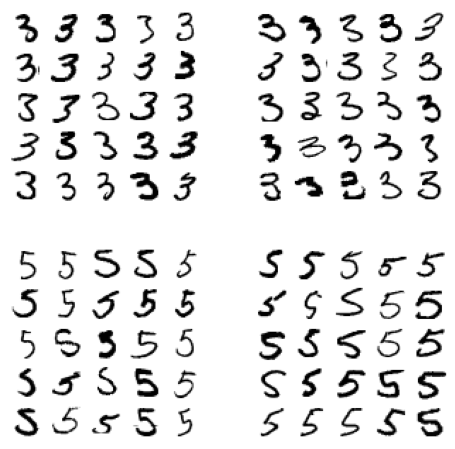

In [172]:
cl_a, cl_b = 3, 5
X_aa = X_train[(y_train == cl_a) & (y_train_pred == cl_a)]
X_ab = X_train[(y_train == cl_a) & (y_train_pred == cl_b)]
X_ba = X_train[(y_train == cl_b) & (y_train_pred == cl_a)]
X_bb = X_train[(y_train == cl_b) & (y_train_pred == cl_b)]

plt.figure(figsize=(8,8))
plt.subplot(221); plot_digits(X_aa[:25], images_per_row=5)
plt.subplot(222); plot_digits(X_ab[:25], images_per_row=5)
plt.subplot(223); plot_digits(X_ba[:25], images_per_row=5)
plt.subplot(224); plot_digits(X_bb[:25], images_per_row=5)
plt.show()

The reason the model seems to be making obvious (for a human) mistakes is that we used a simple `SGDClassifier` , which is a linear model. 
- All it does is assign a weight per class to each pixel, and when it sees a new image it just sums up the weighted pixel intensities to get a score for each class. 
- So since 3s and 5s differ only by a few pixels, this model will easily confuse them. 

The main difference between 3s and 5s is the position of the small line that joins the top line to the bottom arc. If you draw a 3 with the junction slightly shifted to the left, the classifier might classify it as a 5, and vice versa. 
In other words, this **classifier is quite sensitive to image shifting and rotation**. 
- So one way to reduce the 3/5 confusion would be to **preprocess the images to ensure that they are well centered and not too rotated.** This will probably help reduce other errors as well. 


# Multilabel classification

Until now each instance has always been assigned to just one class. In some cases you may want your classifier to output **multiple classes for each instance.** 

Consider a face-recognition classifier: what should it do if it recognizes several people in the same picture? It should attach one tag per person it recognizes. Say the classifier has been trained to recognize three faces, Alice, Bob, and Charlie. Then when the classifier is shown a picture of Alice and Charlie, it should output `[1, 0, 1]` (meaning “Alice yes, Bob no, Charlie yes”). 
Such a classification system that outputs multiple binary tags is called a **multilabel classification system.** We won’t go into face recognition just yet, but let’s look at a simpler example. 

This code creates a `y_multilabel` array containing two target labels for each digit image: 
- the first indicates whether or not the digit is large (7, 8, or 9), 
- and the second indicates whether or not it is odd. 

The next lines create a `KNeighborsClassifier` instance (which supports multilabel classification, though not all classifiers do), 


In [173]:
from sklearn.neighbors import KNeighborsClassifier

y_train_large = (y_train >= 7)
y_train_odd = (y_train % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd]

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_multilabel)

KNeighborsClassifier()

In [174]:
knn_clf.predict([some_digit])

array([[False,  True]])

And it gets it right! The digit 5 is indeed not large ( False ) and odd ( True ). 

There are many ways to evaluate a multilabel classifier, and **selecting the right metric really depends on your project.** 

One approach is to measure the F1-score for each individual label (or any other binary classifier metric discussed earlier), then simply compute the average score. This code computes the average F1-score across all labels: 


In [176]:
%%time
# about 30 s
y_train_knn_pred = cross_val_predict(knn_clf, X_train, y_multilabel, cv=3, n_jobs=-1)

CPU times: user 61.4 ms, sys: 100 ms, total: 162 ms
Wall time: 40.6 s


In [177]:
f1_score(y_multilabel, y_train_knn_pred, average="macro")

0.9761598980762067

This assumes that all labels are equally important, however, which may not be the case. 
In particular, if you have many more pictures of Alice than of Bob or Charlie, you may want to give more weight to the classifier’s score on pictures of Alice. 
- One simple option is to give each label a weight equal to its support (i.e., the number of instances with that target label). To do this, simply set `average="weighted"` in the preceding code.


In [178]:
f1_score(y_multilabel, y_train_knn_pred, average="weighted")

0.9777741190196163

# Multioutput classification

The last type of classification task we are going to discuss here is called **multioutput–multiclass classification (or simply multioutput classification ).** 

It is simply a **generalization of multilabel classification where each label can be multiclass (i.e., it can have more than two possible values).** 

To illustrate this, let’s build a system that removes noise from images. 
- It will take as input a noisy digit image, and it will (hopefully) output a clean digit image, represented as an array of pixel intensities, just like the MNIST images. 
- Notice that the classifier’s output is multilabel **(one label per pixel)** and each label can have multiple values **(pixel intensity ranges from 0 to 255)**. It is thus an example of a multioutput classification system. 


In [179]:
noise = np.random.randint(0, 100, (len(X_train), 784))
X_train_mod = X_train + noise
noise = np.random.randint(0, 100, (len(X_test), 784))
X_test_mod = X_test + noise
y_train_mod = X_train
y_test_mod = X_test

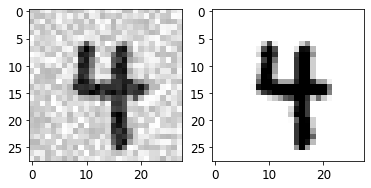

In [184]:
some_index = 5000
plt.subplot(121); plot_digit(X_test_mod[some_index])
plt.subplot(122); plot_digit(y_test_mod[some_index])
plt.show()

In [185]:
X_train_mod.shape

(52500, 784)

In [186]:
y_train_mod.shape

(52500, 784)

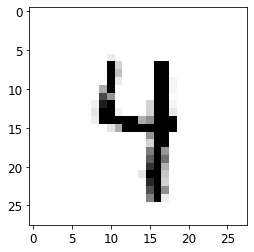

In [187]:
knn_clf.fit(X_train_mod, y_train_mod)
clean_digit = knn_clf.predict([X_test_mod[some_index]])
plot_digit(clean_digit)


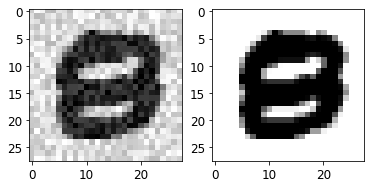

In [188]:
some_index = 5500
plt.subplot(121); plot_digit(X_test_mod[some_index])
plt.subplot(122); plot_digit(y_test_mod[some_index])
plt.show()

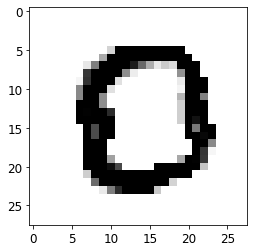

In [189]:
knn_clf.fit(X_train_mod, y_train_mod)
clean_digit = knn_clf.predict([X_test_mod[some_index]])
plot_digit(clean_digit)

# Extra material

## Dummy (ie. random) classifier

In [190]:
from sklearn.dummy import DummyClassifier
dmy_clf = DummyClassifier()
y_probas_dmy = cross_val_predict(dmy_clf, X_train, y_train_5, cv=3, method="predict_proba")
y_scores_dmy = y_probas_dmy[:, 1]

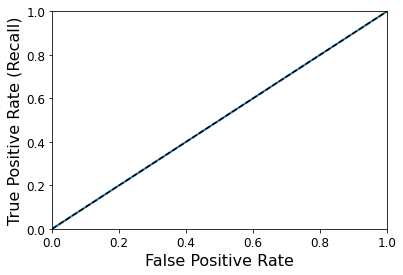

In [191]:
fprr, tprr, thresholdsr = roc_curve(y_train_5, y_scores_dmy)
plot_roc_curve(fprr, tprr)

## KNN classifier

In [14]:
from sklearn.neighbors import KNeighborsClassifier
knn_clf = KNeighborsClassifier(n_jobs=-1, weights='distance', n_neighbors=4)
knn_clf.fit(X_train, y_train)

KNeighborsClassifier(n_jobs=-1, n_neighbors=4, weights='distance')

In [ ]:
y_knn_pred = knn_clf.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_knn_pred)

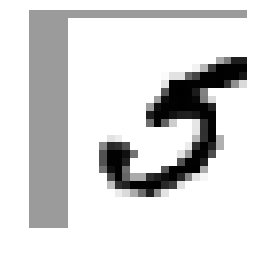

In [ ]:
from scipy.ndimage.interpolation import shift
def shift_digit(digit_array, dx, dy, new=0):
    return shift(digit_array.reshape(28, 28), [dy, dx], cval=new).reshape(784)

plot_digit(shift_digit(some_digit, 5, 1, new=100))

In [ ]:
X_train_expanded = [X_train]
y_train_expanded = [y_train]
for dx, dy in ((1, 0), (-1, 0), (0, 1), (0, -1)):
    shifted_images = np.apply_along_axis(shift_digit, axis=1, arr=X_train, dx=dx, dy=dy)
    X_train_expanded.append(shifted_images)
    y_train_expanded.append(y_train)

X_train_expanded = np.concatenate(X_train_expanded)
y_train_expanded = np.concatenate(y_train_expanded)
X_train_expanded.shape, y_train_expanded.shape

((300000, 784), (300000,))

In [ ]:
knn_clf.fit(X_train_expanded, y_train_expanded)

KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
           metric_params=None, n_jobs=-1, n_neighbors=4, p=2,
           weights='distance')

In [ ]:
y_knn_expanded_pred = knn_clf.predict(X_test)

In [ ]:
accuracy_score(y_test, y_knn_expanded_pred)

0.97629999999999995

In [ ]:
ambiguous_digit = X_test[2589]
knn_clf.predict_proba([ambiguous_digit])

array([[ 0.       ,  0.       ,  0.5053645,  0.       ,  0.       ,
         0.       ,  0.       ,  0.4946355,  0.       ,  0.       ]])

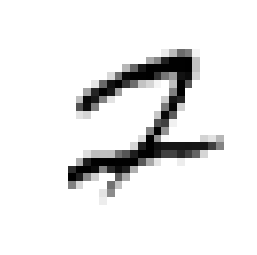

In [ ]:
plot_digit(ambiguous_digit)

# Exercise solutions

## 1. An MNIST Classifier With Over 97% Accuracy

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = [{'weights': ["uniform", "distance"], 'n_neighbors': [3, 4, 5]}]

knn_clf = KNeighborsClassifier()
grid_search = GridSearchCV(knn_clf, param_grid, cv=5, verbose=3, n_jobs=-1)
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] n_neighbors=3, weights=uniform ..................................
[CV]  n_neighbors=3, weights=uniform, score=0.9698458975426906, total= 9.6min
[CV] n_neighbors=3, weights=uniform ..................................


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed: 47.8min remaining:    0.0s


[CV]  n_neighbors=3, weights=uniform, score=0.9714214297617064, total= 9.9min
[CV] n_neighbors=3, weights=uniform ..................................


[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed: 95.2min remaining:    0.0s


[CV]  n_neighbors=3, weights=uniform, score=0.9726666666666667, total= 9.5min
[CV] n_neighbors=3, weights=uniform ..................................
[CV]  n_neighbors=3, weights=uniform, score=0.9728265399683255, total= 9.6min
[CV] n_neighbors=3, weights=uniform ..................................
[CV]  n_neighbors=3, weights=uniform, score=0.9717405801933978, total= 9.6min
[CV] n_neighbors=3, weights=distance .................................
[CV]  n_neighbors=3, weights=distance, score=0.9712619741774261, total= 9.5min
[CV] n_neighbors=3, weights=distance .................................
[CV]  n_neighbors=3, weights=distance, score=0.9725879020163306, total= 9.5min
[CV] n_neighbors=3, weights=distance .................................
[CV] .... n_neighbors=3, weights=distance, score=0.9745, total= 9.5min
[CV] n_neighbors=3, weights=distance .................................
[CV]  n_neighbors=3, weights=distance, score=0.9743269150620989, total= 9.6min
[CV] n_neighbors=3, weights=dist

[Parallel(n_jobs=1)]: Done  30 out of  30 | elapsed: 1399.4min finished


GridSearchCV(cv=5, error_score='raise',
       estimator=KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
           metric_params=None, n_jobs=1, n_neighbors=5, p=2,
           weights='uniform'),
       fit_params=None, iid=True, n_jobs=1,
       param_grid=[{'n_neighbors': [3, 4, 5], 'weights': ['uniform', 'distance']}],
       pre_dispatch='2*n_jobs', refit=True, return_train_score=True,
       scoring=None, verbose=3)

In [ ]:
grid_search.best_params_

{'n_neighbors': 4, 'weights': 'distance'}

In [ ]:
grid_search.best_score_

0.97324999999999995

In [ ]:
from sklearn.metrics import accuracy_score

y_pred = grid_search.predict(X_test)
accuracy_score(y_test, y_pred)

0.97140000000000004

## 2. Data Augmentation

In [ ]:
from scipy.ndimage.interpolation import shift

In [ ]:
def shift_image(image, dx, dy):
    image = image.reshape((28, 28))
    shifted_image = shift(image, [dy, dx], cval=0, mode="constant")
    return shifted_image.reshape([-1])

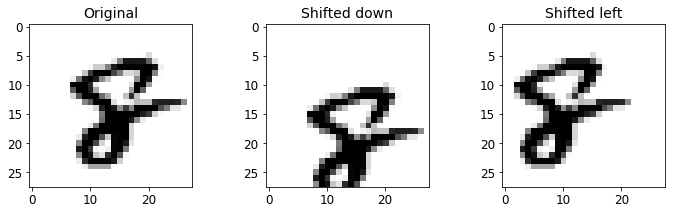

In [ ]:
image = X_train[1000]
shifted_image_down = shift_image(image, 0, 5)
shifted_image_left = shift_image(image, -5, 0)

plt.figure(figsize=(12,3))
plt.subplot(131)
plt.title("Original", fontsize=14)
plt.imshow(image.reshape(28, 28), interpolation="nearest", cmap="Greys")
plt.subplot(132)
plt.title("Shifted down", fontsize=14)
plt.imshow(shifted_image_down.reshape(28, 28), interpolation="nearest", cmap="Greys")
plt.subplot(133)
plt.title("Shifted left", fontsize=14)
plt.imshow(shifted_image_left.reshape(28, 28), interpolation="nearest", cmap="Greys")
plt.show()

In [ ]:
X_train_augmented = [image for image in X_train]
y_train_augmented = [label for label in y_train]

for dx, dy in ((1, 0), (-1, 0), (0, 1), (0, -1)):
    for image, label in zip(X_train, y_train):
        X_train_augmented.append(shift_image(image, dx, dy))
        y_train_augmented.append(label)

X_train_augmented = np.array(X_train_augmented)
y_train_augmented = np.array(y_train_augmented)

In [ ]:
shuffle_idx = np.random.permutation(len(X_train_augmented))
X_train_augmented = X_train_augmented[shuffle_idx]
y_train_augmented = y_train_augmented[shuffle_idx]

In [ ]:
knn_clf = KNeighborsClassifier(**grid_search.best_params_)

In [ ]:
knn_clf.fit(X_train_augmented, y_train_augmented)

KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
           metric_params=None, n_jobs=1, n_neighbors=4, p=2,
           weights='distance')

In [ ]:
y_pred = knn_clf.predict(X_test)
accuracy_score(y_test, y_pred)

0.97629999999999995

By simply augmenting the data, we got a 0.5% accuracy boost. :)

## 3. Tackle the Titanic dataset

The goal is to predict whether or not a passenger survived based on attributes such as their age, sex, passenger class, where they embarked and so on.

First, login to [Kaggle](https://www.kaggle.com/) and go to the [Titanic challenge](https://www.kaggle.com/c/titanic) to download `train.csv` and `test.csv`. Save them to the `datasets/titanic` directory.

Next, let's load the data:

In [ ]:
import os

TITANIC_PATH = os.path.join("datasets", "titanic")

In [ ]:
import pandas as pd

def load_titanic_data(filename, titanic_path=TITANIC_PATH):
    csv_path = os.path.join(titanic_path, filename)
    return pd.read_csv(csv_path)

In [ ]:
train_data = load_titanic_data("train.csv")
test_data = load_titanic_data("test.csv")

The data is already split into a training set and a test set. However, the test data does *not* contain the labels: your goal is to train the best model you can using the training data, then make your predictions on the test data and upload them to Kaggle to see your final score.

Let's take a peek at the top few rows of the training set:

In [ ]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


The attributes have the following meaning:
* **Survived**: that's the target, 0 means the passenger did not survive, while 1 means he/she survived.
* **Pclass**: passenger class.
* **Name**, **Sex**, **Age**: self-explanatory
* **SibSp**: how many siblings & spouses of the passenger aboard the Titanic.
* **Parch**: how many children & parents of the passenger aboard the Titanic.
* **Ticket**: ticket id
* **Fare**: price paid (in pounds)
* **Cabin**: passenger's cabin number
* **Embarked**: where the passenger embarked the Titanic

Let's get more info to see how much data is missing:

In [ ]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
PassengerId    891 non-null int64
Survived       891 non-null int64
Pclass         891 non-null int64
Name           891 non-null object
Sex            891 non-null object
Age            714 non-null float64
SibSp          891 non-null int64
Parch          891 non-null int64
Ticket         891 non-null object
Fare           891 non-null float64
Cabin          204 non-null object
Embarked       889 non-null object
dtypes: float64(2), int64(5), object(5)
memory usage: 83.6+ KB


Okay, the **Age**, **Cabin** and **Embarked** attributes are sometimes null (less than 891 non-null), especially the **Cabin** (77% are null). We will ignore the **Cabin** for now and focus on the rest. The **Age** attribute has about 19% null values, so we will need to decide what to do with them. Replacing null values with the median age seems reasonable.

The **Name** and **Ticket** attributes may have some value, but they will be a bit tricky to convert into useful numbers that a model can consume. So for now, we will ignore them.

Let's take a look at the numerical attributes:

In [ ]:
train_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


* Yikes, only 38% **Survived**. :(  That's close enough to 40%, so accuracy will be a reasonable metric to evaluate our model.
* The mean **Fare** was £32.20, which does not seem so expensive (but it was probably a lot of money back then).
* The mean **Age** was less than 30 years old.

Let's check that the target is indeed 0 or 1:

In [ ]:
train_data["Survived"].value_counts()

0    549
1    342
Name: Survived, dtype: int64

Now let's take a quick look at all the categorical attributes:

In [ ]:
train_data["Pclass"].value_counts()

3    491
1    216
2    184
Name: Pclass, dtype: int64

In [ ]:
train_data["Sex"].value_counts()

male      577
female    314
Name: Sex, dtype: int64

In [ ]:
train_data["Embarked"].value_counts()

S    644
C    168
Q     77
Name: Embarked, dtype: int64

The Embarked attribute tells us where the passenger embarked: C=Cherbourg, Q=Queenstown, S=Southampton.

Now let's build our preprocessing pipelines. We will reuse the `DataframeSelector` we built in the previous chapter to select specific attributes from the `DataFrame`:

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

# A class to select numerical or categorical columns 
# since Scikit-Learn doesn't handle DataFrames yet
class DataFrameSelector(BaseEstimator, TransformerMixin):
    def __init__(self, attribute_names):
        self.attribute_names = attribute_names
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.attribute_names]

Let's build the pipeline for the numerical attributes:

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Imputer

imputer = Imputer(strategy="median")

num_pipeline = Pipeline([
        ("select_numeric", DataFrameSelector(["Age", "SibSp", "Parch", "Fare"])),
        ("imputer", Imputer(strategy="median")),
    ])

In [ ]:
num_pipeline.fit_transform(train_data)

array([[22.    ,  1.    ,  0.    ,  7.25  ],
       [38.    ,  1.    ,  0.    , 71.2833],
       [26.    ,  0.    ,  0.    ,  7.925 ],
       ...,
       [28.    ,  1.    ,  2.    , 23.45  ],
       [26.    ,  0.    ,  0.    , 30.    ],
       [32.    ,  0.    ,  0.    ,  7.75  ]])

We will also need an imputer for the string categorical columns (the regular `Imputer` does not work on those):

In [ ]:
# Inspired from stackoverflow.com/questions/25239958
class MostFrequentImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.most_frequent_ = pd.Series([X[c].value_counts().index[0] for c in X],
                                        index=X.columns)
        return self
    def transform(self, X, y=None):
        return X.fillna(self.most_frequent_)

We can convert each categorical value to a one-hot vector using a `OneHotEncoder`. Right now this class can only handle integer categorical inputs, but in Scikit-Learn 0.20 it will also handle string categorical inputs (see [PR #10521](https://github.com/scikit-learn/scikit-learn/issues/10521)). So for now we import it from `future_encoders.py`, but when Scikit-Learn 0.20 is released, you can import it from `sklearn.preprocessing` instead:

In [ ]:
from future_encoders import OneHotEncoder

Now we can build the pipeline for the categorical attributes:

In [ ]:
cat_pipeline = Pipeline([
        ("select_cat", DataFrameSelector(["Pclass", "Sex", "Embarked"])),
        ("imputer", MostFrequentImputer()),
        ("cat_encoder", OneHotEncoder(sparse=False)),
    ])

In [ ]:
cat_pipeline.fit_transform(train_data)

array([[0., 0., 1., ..., 0., 0., 1.],
       [1., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 1.],
       ...,
       [0., 0., 1., ..., 0., 0., 1.],
       [1., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 1., 0.]])

Finally, let's join the numerical and categorical pipelines:

In [ ]:
from sklearn.pipeline import FeatureUnion
preprocess_pipeline = FeatureUnion(transformer_list=[
        ("num_pipeline", num_pipeline),
        ("cat_pipeline", cat_pipeline),
    ])

Cool! Now we have a nice preprocessing pipeline that takes the raw data and outputs numerical input features that we can feed to any Machine Learning model we want.

In [ ]:
X_train = preprocess_pipeline.fit_transform(train_data)
X_train

array([[22.,  1.,  0., ...,  0.,  0.,  1.],
       [38.,  1.,  0., ...,  1.,  0.,  0.],
       [26.,  0.,  0., ...,  0.,  0.,  1.],
       ...,
       [28.,  1.,  2., ...,  0.,  0.,  1.],
       [26.,  0.,  0., ...,  1.,  0.,  0.],
       [32.,  0.,  0., ...,  0.,  1.,  0.]])

Let's not forget to get the labels:

In [ ]:
y_train = train_data["Survived"]

We are now ready to train a classifier. Let's start with an `SVC`:

In [ ]:
from sklearn.svm import SVC

svm_clf = SVC()
svm_clf.fit(X_train, y_train)

SVC(C=1.0, cache_size=200, class_weight=None, coef0=0.0,
  decision_function_shape='ovr', degree=3, gamma='auto', kernel='rbf',
  max_iter=-1, probability=False, random_state=None, shrinking=True,
  tol=0.001, verbose=False)

Great, our model is trained, let's use it to make predictions on the test set:

In [ ]:
X_test = preprocess_pipeline.transform(test_data)
y_pred = svm_clf.predict(X_test)

And now we could just build a CSV file with these predictions (respecting the format excepted by Kaggle), then upload it and hope for the best. But wait! We can do better than hope. Why don't we use cross-validation to have an idea of how good our model is?

In [ ]:
from sklearn.model_selection import cross_val_score

svm_scores = cross_val_score(svm_clf, X_train, y_train, cv=10)
svm_scores.mean()

0.7365250822835092

Okay, over 73% accuracy, clearly better than random chance, but it's not a great score. Looking at the [leaderboard](https://www.kaggle.com/c/titanic/leaderboard) for the Titanic competition on Kaggle, you can see that you need to reach above 80% accuracy to be within the top 10% Kagglers. Some reached 100%, but since you can easily find the [list of victims](https://www.encyclopedia-titanica.org/titanic-victims/) of the Titanic, it seems likely that there was little Machine Learning involved in their performance! ;-) So let's try to build a model that reaches 80% accuracy.

Let's try a `RandomForestClassifier`:

In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(random_state=42)
forest_scores = cross_val_score(forest_clf, X_train, y_train, cv=10)
forest_scores.mean()

0.8115690614005221

That's much better!

Instead of just looking at the mean accuracy across the 10 cross-validation folds, let's plot all 10 scores for each model, along with a box plot highlighting the lower and upper quartiles, and "whiskers" showing the extent of the scores (thanks to Nevin Yilmaz for suggesting this visualization). Note that the `boxplot()` function detects outliers (called "fliers") and does not include them within the whiskers. Specifically, if the lower quartile is $Q_1$ and the upper quartile is $Q_3$, then the interquartile range $IQR = Q_3 - Q_1$ (this is the box's height), and any score lower than $Q_1 - 1.5 \times IQR$ is a flier, and so is any score greater than $Q3 + 1.5 \times IQR$.

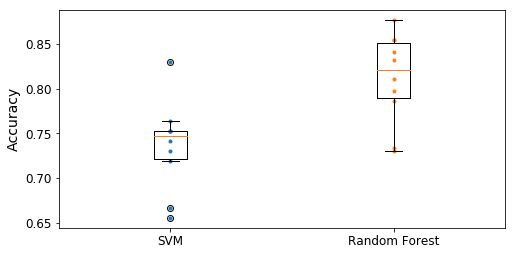

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot([1]*10, svm_scores, ".")
plt.plot([2]*10, forest_scores, ".")
plt.boxplot([svm_scores, forest_scores], labels=("SVM","Random Forest"))
plt.ylabel("Accuracy", fontsize=14)
plt.show()

To improve this result further, you could:
* Compare many more models and tune hyperparameters using cross validation and grid search,
* Do more feature engineering, for example:
  * replace **SibSp** and **Parch** with their sum,
  * try to identify parts of names that correlate well with the **Survived** attribute (e.g. if the name contains "Countess", then survival seems more likely),
* try to convert numerical attributes to categorical attributes: for example, different age groups had very different survival rates (see below), so it may help to create an age bucket category and use it instead of the age. Similarly, it may be useful to have a special category for people traveling alone since only 30% of them survived (see below).

In [ ]:
train_data["AgeBucket"] = train_data["Age"] // 15 * 15
train_data[["AgeBucket", "Survived"]].groupby(['AgeBucket']).mean()

,Survived
AgeBucket,
0.0,0.576923
15.0,0.362745
30.0,0.423256
45.0,0.404494
60.0,0.240000
75.0,1.000000


In [ ]:
train_data["RelativesOnboard"] = train_data["SibSp"] + train_data["Parch"]
train_data[["RelativesOnboard", "Survived"]].groupby(['RelativesOnboard']).mean()

,Survived
RelativesOnboard,
0,0.303538
1,0.552795
2,0.578431
3,0.724138
4,0.200000
5,0.136364
6,0.333333
7,0.000000
10,0.000000


## 4. Spam classifier

First, let's fetch the data:

In [ ]:
import os
import tarfile
from six.moves import urllib

DOWNLOAD_ROOT = "http://spamassassin.apache.org/old/publiccorpus/"
HAM_URL = DOWNLOAD_ROOT + "20030228_easy_ham.tar.bz2"
SPAM_URL = DOWNLOAD_ROOT + "20030228_spam.tar.bz2"
SPAM_PATH = os.path.join("datasets", "spam")

def fetch_spam_data(spam_url=SPAM_URL, spam_path=SPAM_PATH):
    if not os.path.isdir(spam_path):
        os.makedirs(spam_path)
    for filename, url in (("ham.tar.bz2", HAM_URL), ("spam.tar.bz2", SPAM_URL)):
        path = os.path.join(spam_path, filename)
        if not os.path.isfile(path):
            urllib.request.urlretrieve(url, path)
        tar_bz2_file = tarfile.open(path)
        tar_bz2_file.extractall(path=SPAM_PATH)
        tar_bz2_file.close()

In [ ]:
fetch_spam_data()

Next, let's load all the emails:

In [ ]:
HAM_DIR = os.path.join(SPAM_PATH, "easy_ham")
SPAM_DIR = os.path.join(SPAM_PATH, "spam")
ham_filenames = [name for name in sorted(os.listdir(HAM_DIR)) if len(name) > 20]
spam_filenames = [name for name in sorted(os.listdir(SPAM_DIR)) if len(name) > 20]

In [ ]:
len(ham_filenames)

2500

In [ ]:
len(spam_filenames)

500

In [ ]:
spam_filenames[0]

'00001.7848dde101aa985090474a91ec93fcf0'

We can use Python's `email` module to parse these emails (this handles headers, encoding, and so on):

In [ ]:
import email
import email.policy

def load_email(is_spam, filename, spam_path=SPAM_PATH):
    directory = "spam" if is_spam else "easy_ham"
    with open(os.path.join(spam_path, directory, filename), "rb") as f:
        return email.parser.BytesParser(policy=email.policy.default).parse(f)

In [ ]:
ham_emails = [load_email(is_spam=False, filename=name) for name in ham_filenames]
spam_emails = [load_email(is_spam=True, filename=name) for name in spam_filenames]

Let's look at one example of ham and one example of spam, to get a feel of what the data looks like:

In [ ]:
print(ham_emails[0].get_content())

    Date:        Wed, 21 Aug 2002 10:54:46 -0500
    From:        Chris Garrigues <cwg-dated-1030377287.06fa6d@DeepEddy.Com>
    Message-ID:  <1029945287.4797.TMDA@deepeddy.vircio.com>


  | I can't reproduce this error.

For me it is very repeatable... (like every time, without fail).

This is the debug log of the pick happening ...

18:19:03 Pick_It {exec pick +inbox -list -lbrace -lbrace -subject ftp -rbrace -rbrace} {4852-4852 -sequence mercury}
18:19:03 exec pick +inbox -list -lbrace -lbrace -subject ftp -rbrace -rbrace 4852-4852 -sequence mercury
18:19:04 Ftoc_PickMsgs {{1 hit}}
18:19:04 Marking 1 hits
18:19:04 tkerror: syntax error in expression "int ...

Note, if I run the pick command by hand ...

delta$ pick +inbox -list -lbrace -lbrace -subject ftp -rbrace -rbrace  4852-4852 -sequence mercury
1 hit

That's where the "1 hit" comes from (obviously).  The version of nmh I'm
using is ...

delta$ pick -version
pick -- nmh-1.0.4 [compiled on fuchsia.cs.mu.OZ.AU at Sun Mar 17 14:55

In [ ]:
print(ham_emails[1].get_content().strip())

Martin A posted:
Tassos Papadopoulos, the Greek sculptor behind the plan, judged that the
 limestone of Mount Kerdylio, 70 miles east of Salonika and not far from the
 Mount Athos monastic community, was ideal for the patriotic sculpture. 
 
 As well as Alexander's granite features, 240 ft high and 170 ft wide, a
 museum, a restored amphitheatre and car park for admiring crowds are
planned
---------------------
So is this mountain limestone or granite?
If it's limestone, it'll weather pretty fast.

------------------------ Yahoo! Groups Sponsor ---------------------~-->
4 DVDs Free +s&p Join Now
http://us.click.yahoo.com/pt6YBB/NXiEAA/mG3HAA/7gSolB/TM
---------------------------------------------------------------------~->

To unsubscribe from this group, send an email to:
forteana-unsubscribe@egroups.com

 

Your use of Yahoo! Groups is subject to http://docs.yahoo.com/info/terms/


In [ ]:
print(spam_emails[6].get_content().strip())

Help wanted.  We are a 14 year old fortune 500 company, that is
growing at a tremendous rate.  We are looking for individuals who
want to work from home.

This is an opportunity to make an excellent income.  No experience
is required.  We will train you.

So if you are looking to be employed from home with a career that has
vast opportunities, then go:

http://www.basetel.com/wealthnow

We are looking for energetic and self motivated people.  If that is you
than click on the link and fill out the form, and one of our
employement specialist will contact you.

To be removed from our link simple go to:

http://www.basetel.com/remove.html


4139vOLW7-758DoDY1425FRhM1-764SMFc8513fCsLl40


Some emails are actually multipart, with images and attachments (which can have their own attachments). Let's look at the various types of structures we have:

In [ ]:
def get_email_structure(email):
    if isinstance(email, str):
        return email
    payload = email.get_payload()
    if isinstance(payload, list):
        return "multipart({})".format(", ".join([
            get_email_structure(sub_email)
            for sub_email in payload
        ]))
    else:
        return email.get_content_type()

In [ ]:
from collections import Counter

def structures_counter(emails):
    structures = Counter()
    for email in emails:
        structure = get_email_structure(email)
        structures[structure] += 1
    return structures

In [ ]:
structures_counter(ham_emails).most_common()

[('text/plain', 2408),
 ('multipart(text/plain, application/pgp-signature)', 66),
 ('multipart(text/plain, text/html)', 8),
 ('multipart(text/plain, text/plain)', 4),
 ('multipart(text/plain)', 3),
 ('multipart(text/plain, application/octet-stream)', 2),
 ('multipart(text/plain, text/enriched)', 1),
 ('multipart(text/plain, application/ms-tnef, text/plain)', 1),
 ('multipart(multipart(text/plain, text/plain, text/plain), application/pgp-signature)',
  1),
 ('multipart(text/plain, video/mng)', 1),
 ('multipart(text/plain, multipart(text/plain))', 1),
 ('multipart(text/plain, application/x-pkcs7-signature)', 1),
 ('multipart(text/plain, multipart(text/plain, text/plain), text/rfc822-headers)',
  1),
 ('multipart(text/plain, multipart(text/plain, text/plain), multipart(multipart(text/plain, application/x-pkcs7-signature)))',
  1),
 ('multipart(text/plain, application/x-java-applet)', 1)]

In [ ]:
structures_counter(spam_emails).most_common()

[('text/plain', 218),
 ('text/html', 183),
 ('multipart(text/plain, text/html)', 45),
 ('multipart(text/html)', 20),
 ('multipart(text/plain)', 19),
 ('multipart(multipart(text/html))', 5),
 ('multipart(text/plain, image/jpeg)', 3),
 ('multipart(text/html, application/octet-stream)', 2),
 ('multipart(multipart(text/html), application/octet-stream, image/jpeg)', 1),
 ('multipart(text/html, text/plain)', 1),
 ('multipart(multipart(text/plain, text/html), image/gif)', 1),
 ('multipart/alternative', 1),
 ('multipart(text/plain, application/octet-stream)', 1)]

It seems that the ham emails are more often plain text, while spam has quite a lot of HTML. Moreover, quite a few ham emails are signed using PGP, while no spam is. In short, it seems that the email structure is useful information to have.

Now let's take a look at the email headers:

In [ ]:
for header, value in spam_emails[0].items():
    print(header,":",value)

Return-Path : <12a1mailbot1@web.de>
Delivered-To : zzzz@localhost.spamassassin.taint.org
Received : from localhost (localhost [127.0.0.1])	by phobos.labs.spamassassin.taint.org (Postfix) with ESMTP id 136B943C32	for <zzzz@localhost>; Thu, 22 Aug 2002 08:17:21 -0400 (EDT)
Received : from mail.webnote.net [193.120.211.219]	by localhost with POP3 (fetchmail-5.9.0)	for zzzz@localhost (single-drop); Thu, 22 Aug 2002 13:17:21 +0100 (IST)
Received : from dd_it7 ([210.97.77.167])	by webnote.net (8.9.3/8.9.3) with ESMTP id NAA04623	for <zzzz@spamassassin.taint.org>; Thu, 22 Aug 2002 13:09:41 +0100
From : 12a1mailbot1@web.de
Received : from r-smtp.korea.com - 203.122.2.197 by dd_it7  with Microsoft SMTPSVC(5.5.1775.675.6);	 Sat, 24 Aug 2002 09:42:10 +0900
To : dcek1a1@netsgo.com
Subject : Life Insurance - Why Pay More?
Date : Wed, 21 Aug 2002 20:31:57 -1600
MIME-Version : 1.0
Message-ID : <0103c1042001882DD_IT7@dd_it7>
Content-Type : text/html; charset="iso-8859-1"
Content-Transfer-Encoding : qu

There's probably a lot of useful information in there, such as the sender's email address (12a1mailbot1@web.de looks fishy), but we will just focus on the `Subject` header:

In [ ]:
spam_emails[0]["Subject"]

'Life Insurance - Why Pay More?'

Okay, before we learn too much about the data, let's not forget to split it into a training set and a test set:

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

X = np.array(ham_emails + spam_emails)
y = np.array([0] * len(ham_emails) + [1] * len(spam_emails))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Okay, let's start writing the preprocessing functions. First, we will need a function to convert HTML to plain text. Arguably the best way to do this would be to use the great [BeautifulSoup](https://www.crummy.com/software/BeautifulSoup/) library, but I would like to avoid adding another dependency to this project, so let's hack a quick & dirty solution using regular expressions (at the risk of [un̨ho͞ly radiańcé destro҉ying all enli̍̈́̂̈́ghtenment](https://stackoverflow.com/a/1732454/38626)). The following function first drops the `<head>` section, then converts all `<a>` tags to the word HYPERLINK, then it gets rid of all HTML tags, leaving only the plain text. For readability, it also replaces multiple newlines with single newlines, and finally it unescapes html entities (such as `&gt;` or `&nbsp;`):

In [ ]:
import re
from html import unescape

def html_to_plain_text(html):
    text = re.sub('<head.*?>.*?</head>', '', html, flags=re.M | re.S | re.I)
    text = re.sub('<a\s.*?>', ' HYPERLINK ', text, flags=re.M | re.S | re.I)
    text = re.sub('<.*?>', '', text, flags=re.M | re.S)
    text = re.sub(r'(\s*\n)+', '\n', text, flags=re.M | re.S)
    return unescape(text)

Let's see if it works. This is HTML spam:

In [ ]:
html_spam_emails = [email for email in X_train[y_train==1]
                    if get_email_structure(email) == "text/html"]
sample_html_spam = html_spam_emails[7]
print(sample_html_spam.get_content().strip()[:1000], "...")

<HTML><HEAD><TITLE></TITLE><META http-equiv="Content-Type" content="text/html; charset=windows-1252"><STYLE>A:link {TEX-DECORATION: none}A:active {TEXT-DECORATION: none}A:visited {TEXT-DECORATION: none}A:hover {COLOR: #0033ff; TEXT-DECORATION: underline}</STYLE><META content="MSHTML 6.00.2713.1100" name="GENERATOR"></HEAD>
<BODY text="#000000" vLink="#0033ff" link="#0033ff" bgColor="#CCCC99"><TABLE borderColor="#660000" cellSpacing="0" cellPadding="0" border="0" width="100%"><TR><TD bgColor="#CCCC99" valign="top" colspan="2" height="27">
<font size="6" face="Arial, Helvetica, sans-serif" color="#660000">
<b>OTC</b></font></TD></TR><TR><TD height="2" bgcolor="#6a694f">
<font size="5" face="Times New Roman, Times, serif" color="#FFFFFF">
<b>&nbsp;Newsletter</b></font></TD><TD height="2" bgcolor="#6a694f"><div align="right"><font color="#FFFFFF">
<b>Discover Tomorrow's Winners&nbsp;</b></font></div></TD></TR><TR><TD height="25" colspan="2" bgcolor="#CCCC99"><table width="100%" border="0" 

And this is the resulting plain text:

In [ ]:
print(html_to_plain_text(sample_html_spam.get_content())[:1000], "...")


OTC
 Newsletter
Discover Tomorrow's Winners 
For Immediate Release
Cal-Bay (Stock Symbol: CBYI)
Watch for analyst "Strong Buy Recommendations" and several advisory newsletters picking CBYI.  CBYI has filed to be traded on the OTCBB, share prices historically INCREASE when companies get listed on this larger trading exchange. CBYI is trading around 25 cents and should skyrocket to $2.66 - $3.25 a share in the near future.
Put CBYI on your watch list, acquire a position TODAY.
REASONS TO INVEST IN CBYI
A profitable company and is on track to beat ALL earnings estimates!
One of the FASTEST growing distributors in environmental & safety equipment instruments.
Excellent management team, several EXCLUSIVE contracts.  IMPRESSIVE client list including the U.S. Air Force, Anheuser-Busch, Chevron Refining and Mitsubishi Heavy Industries, GE-Energy & Environmental Research.
RAPIDLY GROWING INDUSTRY
Industry revenues exceed $900 million, estimates indicate that there could be as much as $25 billi

Great! Now let's write a function that takes an email as input and returns its content as plain text, whatever its format is:

In [ ]:
def email_to_text(email):
    html = None
    for part in email.walk():
        ctype = part.get_content_type()
        if not ctype in ("text/plain", "text/html"):
            continue
        try:
            content = part.get_content()
        except: # in case of encoding issues
            content = str(part.get_payload())
        if ctype == "text/plain":
            return content
        else:
            html = content
    if html:
        return html_to_plain_text(html)

In [ ]:
print(email_to_text(sample_html_spam)[:100], "...")


OTC
 Newsletter
Discover Tomorrow's Winners 
For Immediate Release
Cal-Bay (Stock Symbol: CBYI)
Wat ...


Let's throw in some stemming! For this to work, you need to install the Natural Language Toolkit ([NLTK](http://www.nltk.org/)). It's as simple as running the following command (don't forget to activate your virtualenv first; if you don't have one, you will likely need administrator rights, or use the `--user` option):

`$ pip3 install nltk`

In [ ]:
try:
    import nltk

    stemmer = nltk.PorterStemmer()
    for word in ("Computations", "Computation", "Computing", "Computed", "Compute", "Compulsive"):
        print(word, "=>", stemmer.stem(word))
except ImportError:
    print("Error: stemming requires the NLTK module.")
    stemmer = None

Computations => comput
Computation => comput
Computing => comput
Computed => comput
Compute => comput
Compulsive => compuls


We will also need a way to replace URLs with the word "URL". For this, we could use hard core [regular expressions](https://mathiasbynens.be/demo/url-regex) but we will just use the [urlextract](https://github.com/lipoja/URLExtract) library. You can install it with the following command (don't forget to activate your virtualenv first; if you don't have one, you will likely need administrator rights, or use the `--user` option):

`$ pip3 install urlextract`

In [ ]:
try:
    import urlextract # may require an Internet connection to download root domain names
    
    url_extractor = urlextract.URLExtract()
    print(url_extractor.find_urls("Will it detect github.com and https://youtu.be/7Pq-S557XQU?t=3m32s"))
except ImportError:
    print("Error: replacing URLs requires the urlextract module.")
    url_extractor = None

['github.com', 'https://youtu.be/7Pq-S557XQU?t=3m32s']


We are ready to put all this together into a transformer that we will use to convert emails to word counters. Note that we split sentences into words using Python's `split()` method, which uses whitespaces for word boundaries. This works for many written languages, but not all. For example, Chinese and Japanese scripts generally don't use spaces between words, and Vietnamese often uses spaces even between syllables. It's okay in this exercise, because the dataset is (mostly) in English.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class EmailToWordCounterTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, strip_headers=True, lower_case=True, remove_punctuation=True,
                 replace_urls=True, replace_numbers=True, stemming=True):
        self.strip_headers = strip_headers
        self.lower_case = lower_case
        self.remove_punctuation = remove_punctuation
        self.replace_urls = replace_urls
        self.replace_numbers = replace_numbers
        self.stemming = stemming
    def fit(self, X, y=None):
        return self
    def transform(self, X, y=None):
        X_transformed = []
        for email in X:
            text = email_to_text(email) or ""
            if self.lower_case:
                text = text.lower()
            if self.replace_urls and url_extractor is not None:
                urls = list(set(url_extractor.find_urls(text)))
                urls.sort(key=lambda url: len(url), reverse=True)
                for url in urls:
                    text = text.replace(url, " URL ")
            if self.replace_numbers:
                text = re.sub(r'\d+(?:\.\d*(?:[eE]\d+))?', 'NUMBER', text)
            if self.remove_punctuation:
                text = re.sub(r'\W+', ' ', text, flags=re.M)
            word_counts = Counter(text.split())
            if self.stemming and stemmer is not None:
                stemmed_word_counts = Counter()
                for word, count in word_counts.items():
                    stemmed_word = stemmer.stem(word)
                    stemmed_word_counts[stemmed_word] += count
                word_counts = stemmed_word_counts
            X_transformed.append(word_counts)
        return np.array(X_transformed)

Let's try this transformer on a few emails:

In [ ]:
X_few = X_train[:3]
X_few_wordcounts = EmailToWordCounterTransformer().fit_transform(X_few)
X_few_wordcounts

array([Counter({'wrote': 1, 'chuck': 1, 'murcko': 1, 'stuff': 1, 'yawn': 1, 'r': 1}),
       Counter({'the': 11, 'of': 9, 'and': 8, 'by': 3, 'christian': 3, 'all': 3, 'to': 3, 'have': 2, 'jesu': 2, 'superstit': 2, 'been': 2, 'teach': 2, 'on': 2, 'jefferson': 2, 'one': 2, 'half': 2, 'ha': 2, 'i': 2, 'rogueri': 2, 'upon': 1, 'earth': 1, 'band': 1, 'fine': 1, 'find': 1, 'men': 1, 'first': 1, 'million': 1, 'error': 1, 'burnt': 1, 'import': 1, 'pervert': 1, 'led': 1, 'coercion': 1, 'make': 1, 'a': 1, 'thi': 1, 'in': 1, 'redeem': 1, 'over': 1, 'remsburg': 1, 'perpetr': 1, 'great': 1, 'e': 1, 'known': 1, 'corrupt': 1, 'again': 1, 'becom': 1, 'introduct': 1, 'examin': 1, 'man': 1, 'mytholog': 1, 'dupe': 1, 'paul': 1, 'word': 1, 'tortur': 1, 'other': 1, 'hypocrit': 1, 'quot': 1, 'most': 1, 'women': 1, 'fabl': 1, 'were': 1, 'six': 1, 'children': 1, 'ever': 1, 'william': 1, 'some': 1, 'john': 1, 'alik': 1, 'interest': 1, 'fool': 1, 'american': 1, 'they': 1, 'sinc': 1, 'url': 1, 'world': 1, 'not':

This looks about right!

Now we have the word counts, and we need to convert them to vectors. For this, we will build another transformer whose `fit()` method will build the vocabulary (an ordered list of the most common words) and whose `transform()` method will use the vocabulary to convert word counts to vectors. The output is a sparse matrix.

In [ ]:
from scipy.sparse import csr_matrix

class WordCounterToVectorTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, vocabulary_size=1000):
        self.vocabulary_size = vocabulary_size
    def fit(self, X, y=None):
        total_count = Counter()
        for word_count in X:
            for word, count in word_count.items():
                total_count[word] += min(count, 10)
        most_common = total_count.most_common()[:self.vocabulary_size]
        self.most_common_ = most_common
        self.vocabulary_ = {word: index + 1 for index, (word, count) in enumerate(most_common)}
        return self
    def transform(self, X, y=None):
        rows = []
        cols = []
        data = []
        for row, word_count in enumerate(X):
            for word, count in word_count.items():
                rows.append(row)
                cols.append(self.vocabulary_.get(word, 0))
                data.append(count)
        return csr_matrix((data, (rows, cols)), shape=(len(X), self.vocabulary_size + 1))

In [ ]:
vocab_transformer = WordCounterToVectorTransformer(vocabulary_size=10)
X_few_vectors = vocab_transformer.fit_transform(X_few_wordcounts)
X_few_vectors

<3x11 sparse matrix of type '<class 'numpy.int64'>'
	with 20 stored elements in Compressed Sparse Row format>

In [ ]:
X_few_vectors.toarray()

array([[ 6,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [99,  9, 11,  8,  3,  1,  3,  3,  1,  2,  3],
       [65,  1,  0,  2,  3,  5,  1,  0,  2,  1,  0]], dtype=int64)

What does this matrix mean? Well, the 64 in the third row, first column, means that the third email contains 64 words that are not part of the vocabulary. The 1 next to it means that the first word in the vocabulary is present once in this email. The 2 next to it means that the second word is present twice, and so on. You can look at the vocabulary to know which words we are talking about. The first word is "of", the second word is "and", etc.

In [ ]:
vocab_transformer.vocabulary_

{'all': 6,
 'and': 3,
 'by': 7,
 'christian': 10,
 'in': 8,
 'of': 1,
 'on': 9,
 'the': 2,
 'to': 4,
 'url': 5}

We are now ready to train our first spam classifier! Let's transform the whole dataset:

In [ ]:
from sklearn.pipeline import Pipeline

preprocess_pipeline = Pipeline([
    ("email_to_wordcount", EmailToWordCounterTransformer()),
    ("wordcount_to_vector", WordCounterToVectorTransformer()),
])

X_train_transformed = preprocess_pipeline.fit_transform(X_train)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

log_clf = LogisticRegression(random_state=42)
score = cross_val_score(log_clf, X_train_transformed, y_train, cv=3, verbose=3)
score.mean()

[CV]  ................................................................
[CV] .................................. , score=0.98375, total=   0.1s
[CV]  ................................................................
[CV] .................................... , score=0.985, total=   0.1s
[CV]  ................................................................
[CV] ................................... , score=0.9925, total=   0.1s


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.3s finished


0.9870833333333334

Over 98.7%, not bad for a first try! :) However, remember that we are using the "easy" dataset. You can try with the harder datasets, the results won't be so amazing. You would have to try multiple models, select the best ones and fine-tune them using cross-validation, and so on.

But you get the picture, so let's stop now, and just print out the precision/recall we get on the test set:

In [ ]:
from sklearn.metrics import precision_score, recall_score

X_test_transformed = preprocess_pipeline.transform(X_test)

log_clf = LogisticRegression(random_state=42)
log_clf.fit(X_train_transformed, y_train)

y_pred = log_clf.predict(X_test_transformed)

print("Precision: {:.2f}%".format(100 * precision_score(y_test, y_pred)))
print("Recall: {:.2f}%".format(100 * recall_score(y_test, y_pred)))

Precision: 94.90%
Recall: 97.89%
